# Specs or Wearability? What Separates Loved Wearables from Regretted Ones

**Aidan O'Driscoll** · DESIGNTK 530 · Fall 2026 · Midterm project

- **Colab (view link):** [https://colab.research.google.com/drive/1eFKj3Eyc_SLjlJ7hF0gW-NxbfukXkmGz?usp=sharing](https://colab.research.google.com/drive/1eFKj3Eyc_SLjlJ7hF0gW-NxbfukXkmGz?usp=sharing)
- **Dashboard:** [https://wearables-portfolio-hmgmaecqh2rrjigame7xqj.streamlit.app/](https://wearables-portfolio-hmgmaecqh2rrjigame7xqj.streamlit.app/)
- **Portfolio page:** [https://wearables-portfolio.vercel.app](https://wearables-portfolio.vercel.app)
- **Dashboard and page code:** [https://github.com/Aidan-OD-tech/wearables-portfolio](https://github.com/Aidan-OD-tech/wearables-portfolio)

**Summary.** Fitness trackers and smartwatches are sold on sensors and smart features. I wanted to know if that's what separates the ones people love from the ones they regret, or if everyday wearability matters more. I compared 1,929 1–2★ and 1,929 4–5★ Amazon reviews of the same 17 devices, coded them into 10 themes, and read 60 of them by hand.

The answer is neither family as a whole. What separates them is whether the device keeps working. "Breaks or stops working" comes up in 29% of low reviews vs 6% of high ones, more often in low reviews for all 17 products, and it holds when I match review length or use a stricter word list. Leave it out and wearability themes come up about equally in both groups. Comfort, battery, sensors and smart features come up more in happy reviews, and accuracy barely separates them. 94% of the failures that give a date happen in the first year, yet only 2 of 96 listing bullets mention durability. Specs and comfort earn the 5 stars; durability decides the 1 stars.

Section 3 proposes an A/B test of an early check-in for failing devices, Section 4 is the dashboard, and Section 5 compares my work with ChatGPT's. Sources and a file guide are at the end.

In [1]:
# Setup: everything the notebook needs
import html
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 90)

### What changed since Checkpoint 1

At Checkpoint 1 my project was "The Promise Gap": whether smart door locks and thermostats deliver what they promise, using Amazon Reviews 2023 (Tools & Home Improvement, about 301,000 reviews of 8,700 products). After the checkpoint I switched to wearables for two reasons. The scope was off: two product families with three tiers each meant every comparison mixed in price, product age and a few big brands, so it was hard to pin down what the "smart" step itself was doing. And I was more interested in wearables.

What carried over is the approach, not the data or the findings: the same source (a different category), comparing what listings promise with what reviewers say, keyword themes checked against a hand-read sample with a fixed seed (530), and making sure a result isn't driven by a few popular products. What's new is a cleaner comparison: one product type, and the same number of low and high reviews from each product, so the difference comes from the reviews and not from which products are in each group. I also read low *and* high reviews this time, not only negative ones.

One Checkpoint 1 result turned out to matter here too. Even as locks got smarter, "breaks or fails" stayed one of the biggest complaints (about 40% of negative connected-lock reviews).

## 1. Topic, question and audience

Fitness trackers and smartwatches are marketed on what they can measure: heart rate, sleep stages, blood oxygen, GPS, and a growing list of smart features. As a designer, I suspect that's not what decides whether people like living with one. A device that's uncomfortable, needs charging every night, or breaks at the strap can feel like a bad product no matter how good its sensors are.

**Main question:** Which experiences separate highly rated fitness trackers and smartwatches from poorly rated ones: everyday wearability (fit, comfort, materials, battery, reliability) or technical capability (tracking accuracy, sensors, smart features)?

**Supporting questions**
1. How often do 1–2★ and 4–5★ reviews of the same products mention wearability themes compared with technical themes?
2. Which single theme shows the biggest gap between low and high ratings?
3. Do fitness trackers and smartwatches differ?
4. Do product listings lead with technical features more than wearability?

**Audience:** industrial designers, wearable product teams and product managers. If negative feedback is mostly about wearability, that's an argument for putting more design effort into straps, materials, fit and charging, not only into the next sensor.

**Initial expectation:** wearability themes will separate low and high ratings more than technical ones. I'd change my mind if tracking accuracy or feature problems show the biggest gap, or if wearability themes appear about equally often in praise and complaints.

**Objectives:** Compare what people describe in low-star and high-star reviews of the same devices, then turn the strongest differences into design priorities and one testable product change.

My premise that product teams focus on specs is an assumption. I check it partly in 2.11 by looking at what listings promise. Reviews also show dissatisfaction, not whether someone stopped wearing the device.

## 1.1 The data

**Source:** [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/), McAuley Lab, UC San Diego (Hou et al., 2024, *Bridging Language and Items for Retrieval and Recommendation*, [arXiv:2403.03952](https://arxiv.org/abs/2403.03952)). This is a different dataset from the Amazon Sales data I used in I-3.

**Collection:** the lab collected public Amazon.com product pages and reviews. The full dataset covers May 1996 to September 2023 across 33 product categories. I use the **Cell Phones & Accessories** and **Electronics** categories, where Amazon lists smartwatches and fitness trackers.

**What I keep:** named fitness tracker and smartwatch models (not accessories, refurbished units or kids' watches) with enough written 1–2★ reviews. For each product, I sample the same number of 1–2★ and 4–5★ reviews.

| File | One row is | Key fields |
|---|---|---|
| `wearable_products.csv` | one product (color and size variants grouped by `parent_asin`) | device type, brand, price, average rating, rating counts by star, listing feature bullets |
| `wearable_reviews_sample.csv` | one written review of a selected product | rating, rating group, review title and text, helpful votes, verified purchase, date |

The data has numbers (stars, helpful votes, price, review length), categories (device type, brand, rating group, verified purchase) and long free text (reviews and listing bullets).

**Population:** Amazon shoppers who chose to write a review of a popular tracker or smartwatch, up to September 2023. Not all owners, and not wearables in general.

**Known limitations**
- Reviewers choose to write, so very happy and very unhappy people are over-represented, and Amazon ratings skew positive.
- My sample is balanced by design, so it can't tell you how common low ratings are. I keep the real star counts in the products file for that.
- Older models are included, and some reviews may be incentivized. The `verified_purchase` flag helps a little.
- Many products have no listed price.

## 1.2 Getting the data

The category files are several GB, so I pulled the data once in a separate notebook, [`01_data_pull.ipynb`](01_data_pull.ipynb), and saved two small CSVs. This notebook starts from those CSVs.

**How I picked the devices**
- My first pass searched titles for "smartwatch" and "tracker," and most of what it found wasn't a wearable: SIM cards, repair kits, watch bands and a dash cam. So I switched to **named models** (Fitbit Charge, Galaxy Watch, Garmin vívosmart and so on) plus generic listings that call themselves a smartwatch or fitness tracker.
- I dropped accessories, refurbished units (reviews mix up the product and the refurbisher) and kids' watches (a different user).
- Duplicate reviews (the same reviewer and text on two listing variants) were removed, and I capped each brand at 4 products so one brand doesn't fill the sample.

**Is there enough negative feedback?** I set the bar at 2,000+ written 1–2★ reviews and 10+ products with at least 50 each. The result: 34 eligible products, 18 selected (12 smartwatches, 6 trackers), **13,361 written 1–2★ reviews available. Verdict: GO.**

**Sampling:** for each product, up to 120 random 1–2★ and the same number of 4–5★ reviews with at least 40 characters (fixed seed 530). 3★ reviews are left out because they're mixed. Reviewer IDs are hashed. That gives 4,098 reviews.

## 1.3 First look

**To run this notebook:** upload `wearable_products.csv` and `wearable_reviews_sample.csv` (included with my submission) to the Colab files panel, or run the cell below and use the upload button.

In [2]:
FILES = ["wearable_products.csv", "wearable_reviews_sample.csv"]
if not all(Path(f).exists() for f in FILES):
    print("Upload the two CSVs from my submission:", ", ".join(FILES))
    from google.colab import files
    files.upload()

products = pd.read_csv("wearable_products.csv")
reviews = pd.read_csv("wearable_reviews_sample.csv", parse_dates=["review_date"])

print("Products:", products.shape, "| Reviews:", reviews.shape)
display(products[["device_type", "brand", "product_title", "average_rating", "amazon_rating_count", "price_usd"]])
display(reviews.head())

Upload the two CSVs from my submission: wearable_products.csv, wearable_reviews_sample.csv


Saving wearable_reviews_sample.csv to wearable_reviews_sample.csv
Saving wearable_products.csv to wearable_products.csv
Products: (18, 18) | Reviews: (4098, 13)


,device_type,brand,product_title,average_rating,amazon_rating_count,price_usd
0,fitness tracker,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small",4.0,16517,129.02
1,smartwatch,Fitbit,"Fitbit Sense Advanced Smartwatch with Tools for Heart Health, Stress Management & Skin...",4.3,12234,172.56
2,fitness tracker,Fitbit,"Fitbit Flex Wireless Activity + Sleep Wristband, Slate, Small/Large",4.1,4635,NaN
3,smartwatch,Amazfit,"Amazfit Bip Fitness Smartwatch, All-Day Heart Rate and Activity Tracking, Sleep Monito...",4.0,10720,NaN
4,smartwatch,Popglory,"Popglory Smart Watch, Smartwatch with Blood Pressure, Blood Oxygen Monitor, Fitness Tr...",3.9,19862,25.49
5,smartwatch,Garmin,"Garmin 010-01985-01 Vivoactive 3 Music, Gps Smartwatch with Music Storage and Built-In...",4.5,14598,276.25
6,smartwatch,SAMSUNG,"SAMSUNG Galaxy Watch 4 44mm Smartwatch with ECG Monitor Tracker for Health, Fitness, R...",4.6,25548,207.74
7,smartwatch,Garmin,"Garmin vívoactive HR GPS Smart Watch, Regular fit - Black",4.1,5896,NaN
8,smartwatch,Apple,Apple Watch Series 7 [GPS + Cellular 45mm] Smart Watch w/Graphite Stainless Steel Case...,4.8,52130,NaN
9,smartwatch,Garmin,"Garmin 010-01689-00 Forerunner 35; Easy-to-Use GPS Running Watch, Black",4.5,14891,94.49


,review_id,parent_asin,device_type,rating_group,rating,review_title,review_text,helpful_vote,verified_purchase,review_date,reviewer,brand,product_title
0,R00001,B00NWXM5U0,fitness tracker,high (4-5 stars),5.0,AMAZING!!!!,I LOVE my Fitbit Charge!!!!! It works perfectly! I would recomend this product to ever...,1,True,2015-09-21,U3495675565,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small"
1,R00002,B00NWXM5U0,fitness tracker,high (4-5 stars),5.0,"Loved it! Only reason I said ""loved"" because my ...",Shipped quick! Loved it! Only reason I said &#34;loved&#34; because my Puppy decided h...,0,True,2015-10-24,U5697737828,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small"
2,R00003,B00NWXM5U0,fitness tracker,high (4-5 stars),5.0,Great Product,"I got a small and it fits nicely. Love it, it has worked perfectly.",0,True,2015-11-10,U9230256047,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small"
3,R00004,B00NWXM5U0,fitness tracker,high (4-5 stars),5.0,One of my favorite 'gadgets'!!,"Loved my Fitbit Flex, but this new Fitbit Charge is even better!",0,False,2014-12-14,U2233763265,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small"
4,R00005,B00NWXM5U0,fitness tracker,high (4-5 stars),4.0,Four Stars,Bought this as a gift and they like it a lot.,0,True,2016-03-21,U3364948920,Fitbit,"Fitbit Charge Wireless Activity Wristband, Black, Small"


## 2. Cleaning and exploring the data

### 2.1 What's in the review table?

Before cleaning, I check the data types, missing values and duplicates, and confirm the low and high groups are balanced.

In [3]:
print("Reviews:", reviews.shape)
display(reviews.dtypes)
display(reviews.isna().sum())

print("Duplicate review IDs:", reviews["review_id"].duplicated().sum())
print("Duplicate reviewer + text:", reviews.duplicated(["reviewer", "review_text"]).sum())
print("Reviews containing HTML (<br />, &#34;):", reviews["review_text"].str.contains(r"&#?\w+;|<br", regex=True).sum())

display(reviews.groupby(["device_type", "rating_group"]).size().unstack())

Reviews: (4098, 13)


,0
review_id,object
parent_asin,object
device_type,object
rating_group,object
rating,float64
review_title,object
review_text,object
helpful_vote,int64
verified_purchase,bool
review_date,datetime64[ns]


,0
review_id,0
parent_asin,0
device_type,0
rating_group,0
rating,0
review_title,1
review_text,0
helpful_vote,0
verified_purchase,0
review_date,0


Duplicate review IDs: 0
Duplicate reviewer + text: 0
Reviews containing HTML (<br />, &#34;): 837


rating_group,high (4-5 stars),low (1-2 stars)
device_type,,
fitness tracker,609,609
smartwatch,1440,1440


### 2.2 Cleaning

Three changes:
1. **Drop the Samsung Gear IconX.** They're earbuds with a step counter, not a wrist wearable, so they don't fit my question.
2. **Turn HTML back into plain text.** About 800 reviews contain codes like `<br />` and `&#34;`.
3. **Add the fields I need:** whole-number stars, a low-rating flag, word count, year, and `full_text` (title plus review). I code themes on `full_text` because reviewers often put the main complaint in the title, like "Stopped working after 2 months."

I don't remove anything else. There are no duplicates, and the one missing title just becomes blank.

In [4]:
rows_before, products_before = len(reviews), reviews["parent_asin"].nunique()

# 1. Drop the Samsung Gear IconX: earbuds with a step counter, not a wrist wearable
NOT_WEARABLE = ["B01H3EEOD4"]
reviews = reviews[~reviews["parent_asin"].isin(NOT_WEARABLE)].copy()
products = products[~products["parent_asin"].isin(NOT_WEARABLE)].copy()

# 2. Turn HTML back into plain text
def clean_text(s):
    s = html.unescape(str(s))
    return s.replace("<br />", " ").replace("<br/>", " ").replace("<br>", " ").strip()

reviews["review_title"] = reviews["review_title"].fillna("").map(clean_text)
reviews["review_text"] = reviews["review_text"].map(clean_text)

# 3. Fields I'll use later
reviews["stars"] = reviews["rating"].astype(int)
reviews["low_rating"] = reviews["rating_group"].str.startswith("low")
reviews["full_text"] = reviews["review_title"] + ". " + reviews["review_text"]
reviews["word_count"] = reviews["review_text"].str.split().str.len()
reviews["review_year"] = reviews["review_date"].dt.year
reviews = reviews.drop(columns="rating")

print(f"Rows: {rows_before:,} → {len(reviews):,} | products: {products_before} → {reviews['parent_asin'].nunique()}")
print("HTML left:", reviews["review_text"].str.contains(r"&#?\w+;|<br", regex=True).sum())
display(reviews.groupby(["device_type", "rating_group"]).size().unstack())

Rows: 4,098 → 3,858 | products: 18 → 17
HTML left: 0


rating_group,high (4-5 stars),low (1-2 stars)
device_type,,
fitness tracker,489,489
smartwatch,1440,1440


### 2.3 Descriptive statistics

I summarize at two levels. For products, I use the real star counts across every written review in the dataset. For my sample, I look at review length, helpful votes and verified purchases, with the number of reviews behind each summary.

In [5]:
# Real star counts for each product (all written reviews, not my sample)
star_cols = ["n_1star", "n_2star", "n_3star", "n_4star", "n_5star"]
products["share_low"] = (products["n_1star"] + products["n_2star"]) / products[star_cols].sum(axis=1)
products["share_high"] = (products["n_4star"] + products["n_5star"]) / products[star_cols].sum(axis=1)

print("Products by type:")
display(products.groupby("device_type").agg(
    products=("parent_asin", "count"),
    reviews_in_dataset=("reviews_total", "sum"),
    median_avg_rating=("average_rating", "median"),
    median_share_low=("share_low", "median"),
    median_share_high=("share_high", "median"),
    priced=("price_usd", "count"),
    median_price_usd=("price_usd", "median"),
).round(2))

# Review length and helpfulness in my sample
print("\nReview length (words) and helpful votes by rating group:")
display(reviews.groupby("rating_group").agg(
    reviews=("review_id", "count"),
    mean_words=("word_count", "mean"),
    median_words=("word_count", "median"),
    sd_words=("word_count", "std"),
    mean_helpful=("helpful_vote", "mean"),
    median_helpful=("helpful_vote", "median"),
    pct_verified=("verified_purchase", "mean"),
).round(2))

print("\nReviews per brand:")
display(reviews.groupby(["brand", "device_type"]).size().rename("reviews").reset_index()
        .sort_values("reviews", ascending=False))

Products by type:


,products,reviews_in_dataset,median_avg_rating,median_share_low,median_share_high,priced,median_price_usd
device_type,,,,,,,
fitness tracker,5,17410,4.10,0.32,0.60,3,99.93
smartwatch,12,32561,4.25,0.27,0.62,9,94.49



Review length (words) and helpful votes by rating group:


,reviews,mean_words,median_words,sd_words,mean_helpful,median_helpful,pct_verified
rating_group,,,,,,,
high (4-5 stars),1929,63.10,34.0,118.79,1.97,0.0,0.92
low (1-2 stars),1929,75.06,49.0,83.57,2.56,0.0,0.89



Reviews per brand:


,brand,device_type,reviews
6,Garmin,smartwatch,960
3,Fitbit,fitness tracker,480
1,Amazfit,smartwatch,480
9,Xiaomi,fitness tracker,398
0,AGPTEK,smartwatch,240
2,Apple,smartwatch,240
4,Fitbit,smartwatch,240
5,Fitpolo,smartwatch,240
7,Popglory,smartwatch,240
8,SAMSUNG,smartwatch,240


**What this shows**
- **Written reviews are harsher than star averages suggest.** Every product averages 3.6–4.8 stars, yet in the median product about 27% of written reviews are 1–2★ (32% for trackers). The Apple Watch Series 7 averages 4.8, but 18% of its written reviews are low. The average includes star-only ratings, and the people who bother to write lean critical.
- **Low reviews are longer.** The median is 49 words vs. 34 for high reviews. The means (75 vs. 63) are closer because a few very long positive reviews pull the high mean up (SD 119 vs. 84). Unhappy people explain themselves more, which gives me more text to code but also means low reviews have more chances to mention any theme. I'll keep that in mind when comparing rates.
- **Helpful votes are mostly zero** (median 0 in both groups). The mean is driven by a few popular reviews, so I won't lean on it.
- **Garmin makes up a third of smartwatch reviews** (4 products, the maximum I allowed per brand), so smartwatch results lean toward Garmin.
- Only 9 of 12 smartwatches and 3 of 5 trackers have a listed price, so price is a weak variable here.

### 2.4 How ratings and review length are distributed

Two quick views before coding themes. First, how each product's written reviews split across 1–5 stars, using the real counts, not my balanced sample. Second, how review length differs between low and high reviews.

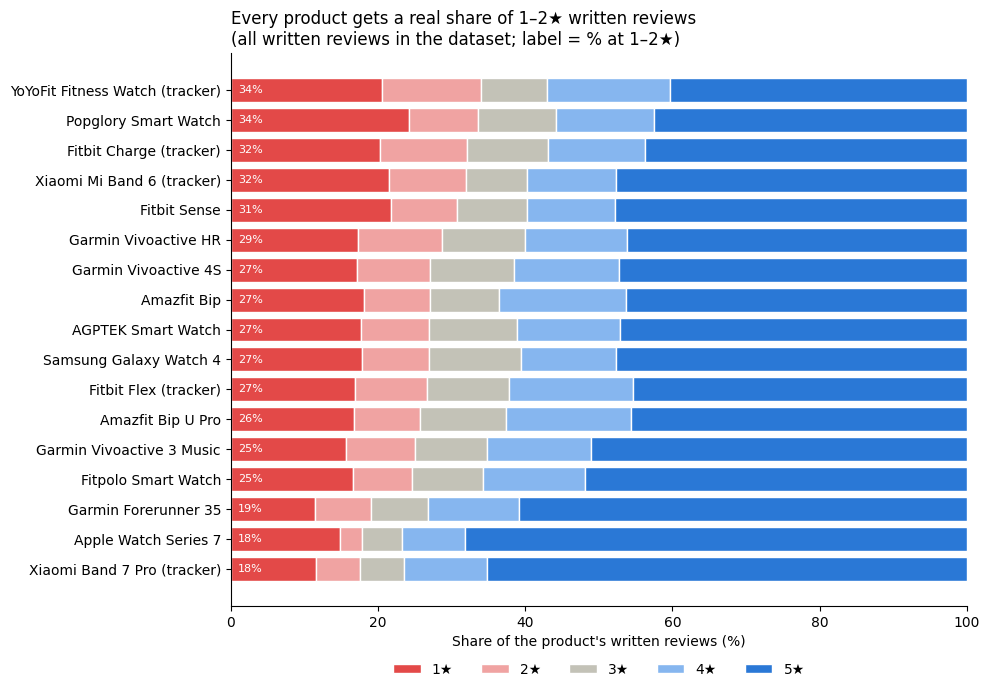

Showing reviews up to 419 words; 39 longer reviews are left off the chart only.


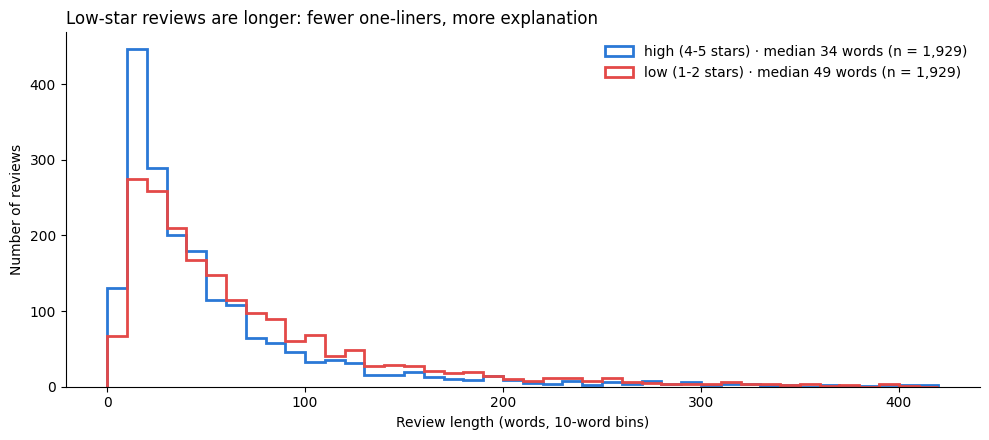

In [6]:
# Short names for charts
SHORT_NAMES = {
    "B00NWXM5U0": "Fitbit Charge", "B00BGO0QEO": "Fitbit Flex", "B08GLRVD95": "Fitbit Sense",
    "B091KPMFXJ": "Xiaomi Mi Band 6", "B0BC3X6ZQ4": "Xiaomi Band 7 Pro", "B07N2CH1S5": "YoYoFit Fitness Watch",
    "B07CRSK5DM": "Amazfit Bip", "B0BJW6R4YX": "Amazfit Bip U Pro", "B0B5WDRB5K": "Popglory Smart Watch",
    "B07M87KRKR": "Garmin Vivoactive 3 Music", "B01BKUB6BA": "Garmin Vivoactive HR", "B08L4V3PNJ": "Garmin Vivoactive 4S",
    "B07R5VHKKZ": "Garmin Forerunner 35", "B0BLD1HN66": "Samsung Galaxy Watch 4", "B09RL7NM59": "Apple Watch Series 7",
    "B08MVYQTRR": "AGPTEK Smart Watch", "B0BJZNZQY7": "Fitpolo Smart Watch",
}
products["short_name"] = products["parent_asin"].map(SHORT_NAMES)
reviews["short_name"] = reviews["parent_asin"].map(SHORT_NAMES)

LOW, HIGH = "#e34948", "#2a78d6"   # same two colors for low and high reviews in every chart
STAR_COLORS = ["#e34948", "#f0a3a2", "#c3c2b7", "#86b6ef", "#2a78d6"]

# Chart 1: how each product's written reviews split across 1–5 stars
products["chart_label"] = products["short_name"] + products["device_type"].map({"fitness tracker": " (tracker)", "smartwatch": ""})
shares = products.set_index("chart_label")[star_cols]
shares = shares.div(shares.sum(axis=1), axis=0) * 100
shares = shares.loc[products.sort_values("share_low").chart_label]

fig, ax = plt.subplots(figsize=(10, 7))
left = pd.Series(0.0, index=shares.index)
for col, color, label in zip(star_cols, STAR_COLORS, ["1★", "2★", "3★", "4★", "5★"]):
    ax.barh(shares.index, shares[col], left=left, color=color, edgecolor="white", linewidth=1, label=label)
    left += shares[col]
for i, (name, row) in enumerate(shares.iterrows()):
    ax.text(1, i, f"{row['n_1star'] + row['n_2star']:.0f}%", va="center", ha="left", fontsize=8, color="white")
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the product's written reviews (%)")
ax.set_title("Every product gets a real share of 1–2★ written reviews\n(all written reviews in the dataset; label = % at 1–2★)", loc="left")
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.15), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Chart 2: review length by rating group, cut at the 99th percentile for readability
cutoff = reviews["word_count"].quantile(0.99)
print(f"Showing reviews up to {cutoff:.0f} words; {(reviews['word_count'] > cutoff).sum()} longer reviews are left off the chart only.")

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = range(0, int(cutoff) + 10, 10)
for group, color in [("high (4-5 stars)", HIGH), ("low (1-2 stars)", LOW)]:
    words = reviews.loc[(reviews.rating_group == group) & (reviews.word_count <= cutoff), "word_count"]
    ax.hist(words, bins=bins, histtype="step", linewidth=2, color=color,
            label=f"{group} · median {reviews.loc[reviews.rating_group == group, 'word_count'].median():.0f} words (n = {(reviews.rating_group == group).sum():,})")
ax.set_xlabel("Review length (words, 10-word bins)")
ax.set_ylabel("Number of reviews")
ax.set_title("Low-star reviews are longer: fewer one-liners, more explanation", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Reading the charts**
- **Every product has a real low-star group:** 18% to 34% of written reviews are 1–2★. The cheap generic watches (YoYoFit, Popglory) and the oldest trackers (Fitbit Charge) sit at the top. Newer premium devices (Apple Watch Series 7, Garmin Forerunner 35, Xiaomi Band 7 Pro) sit at the bottom.
- **1★ beats 2★ for every product.** People who are unhappy tend to go all the way down rather than giving a mild 2★, which suggests something failing outright, not just disappointing.
- **High reviews spike at 10–20 words** ("Love it, works great"), while low reviews spread out into longer explanations. The x-axis stops at the 99th percentile (419 words). That only trims the chart, and the 39 longer reviews stay in the data.
- **What this can't tell me:** the star mix shows that products differ, not why. That's what the theme coding is for.

### 2.5 Coding themes

I sort each review into 10 themes in two families, using keyword lists on the title plus the review text. For each theme, I report the share of reviews that mention it at least once, so long reviews don't count extra.

- **Everyday wearability:** fit & comfort, skin irritation, strap & materials, battery life, charging, breaks or stops working
- **Technical capability:** tracking accuracy, health sensors, smart features, app & syncing

Before settling on the lists, I read a sample of matches for each theme and removed words that caught the wrong thing ("fit" matched "Google Fit," and "band" matched "Mi Band"). A match means the theme was **mentioned**, not whether it was praised or criticized. That's why I compare low and high reviews instead of only counting complaints.

In [7]:
# Theme dictionary: each theme is a set of words or phrases, matched in the title + review text
THEMES = {
    # Everyday wearability
    "Fit & comfort":       r"\bcomfort\w*|uncomfortable|\bfits\b|\bfit (?:my|on|around|well|nicely|perfectly|great|comfortably|snug)|(?:good|great|perfect|poor|bad|snug|loose|tight) fit|too (?:big|small|bulky|heavy|tight|loose)|\bbulky\b|lightweight|(?:too|bit|very|feels?|is) (?:tight|loose)",
    "Skin irritation":     r"\brash\w*|irritat\w*|\bitch\w*|allerg\w*|blister\w*|\bskin\b|burn\w* (?:my |on my )?(?:wrist|skin|arm)|red marks?",
    "Strap & materials":   r"\bstraps?\b|\bclasp\b|\bbuckle\b|(?:replacement|new|watch|silicone|rubber|leather|metal|sport|extra|wrist) ?bands?\b|\bband (?:broke|snapped|tore|ripped|cracked|came)|silicone|rubber|plastic|\bmaterials?\b",
    "Battery life":        r"battery|hold (?:a |its )?charge|lasts? (?:\w+ )?days?|days? (?:on|per) (?:a )?charge",
    "Charging":            r"charger|charging|recharg\w*|\bcharges?\b(?<!fitbit charge)(?! hr| \d)|charge cable|charge it",
    "Breaks or stops working": r"stopped working|stop working|quit working|stops working|\bdied\b|\bdead\b|\bbroke\b|\bbroken\b|fell (?:off|apart)|defective|malfunction\w*|won'?t turn on|cracked|warranty|replacement",
    # Technical capability
    "Tracking accuracy":   r"accura\w*|inaccura\w*|incorrect\w*|\boff by\b|miscount\w*|overcount\w*|undercount\w*|precis\w*",
    "Health sensors":      r"heart rate|\bhr\b|\bbpm\b|\bpulse\b|spo2|oxygen|blood pressure|\becg\b|\bsleep\b|\bsteps?\b|pedometer|calorie\w*|\bgps\b",
    "Smart features":      r"notification\w*|\bnotify\b|\btexts?\b|\bcalls?\b|messages?|\bmusic\b|alexa|assistant|siri|\bpay\b|payment|watch ?faces?|weather",
    "App & syncing":       r"\bapps?\b|\bsync\w*|bluetooth|\bpair\w*|\bconnect\w*|disconnect\w*|\bupdates?\b|firmware|software",
}
FAMILY = {t: "Wearability" for t in list(THEMES)[:6]} | {t: "Technical" for t in list(THEMES)[6:]}

text = reviews["full_text"].str.lower()
for theme, pattern in THEMES.items():
    reviews[theme] = text.str.contains(pattern, regex=True)

reviews["any_wearability"] = reviews[[t for t in THEMES if FAMILY[t] == "Wearability"]].any(axis=1)
reviews["any_technical"] = reviews[[t for t in THEMES if FAMILY[t] == "Technical"]].any(axis=1)

# Share of reviews mentioning each theme, low vs high
rates = (reviews.groupby("rating_group")[list(THEMES)].mean().T * 100).round(1)
rates.columns = ["high %", "low %"]
rates["gap (low − high)"] = rates["low %"] - rates["high %"]
rates["family"] = rates.index.map(FAMILY)
display(rates.sort_values("gap (low − high)", ascending=False))
print("Reviews per group:", reviews["rating_group"].value_counts().to_dict())

,high %,low %,gap (low − high),family
Breaks or stops working,6.1,28.6,22.5,Wearability
App & syncing,27.2,34.5,7.3,Technical
Charging,15.5,20.5,5.0,Wearability
Strap & materials,5.8,8.4,2.6,Wearability
Skin irritation,1.4,2.9,1.5,Wearability
Tracking accuracy,14.9,16.1,1.2,Technical
Smart features,20.5,18.0,-2.5,Technical
Health sensors,36.6,33.1,-3.5,Technical
Fit & comfort,10.4,4.2,-6.2,Wearability
Battery life,26.6,18.9,-7.7,Wearability


Reviews per group: {'high (4-5 stars)': 1929, 'low (1-2 stars)': 1929}


### 2.6 Which themes separate low from high reviews?

Each row shows how often a theme comes up in 1–2★ reviews (red) and 4–5★ reviews (blue). The longer the line, the more that theme separates the two groups. I also give each theme a role based on its gap: a **regret driver** shows up more in low reviews (+2 points or more), a **love driver** shows up more in high reviews (−2 or less), and anything in between is **neutral**. Then I check each theme product by product, so a big overall gap can't come from just one or two devices.

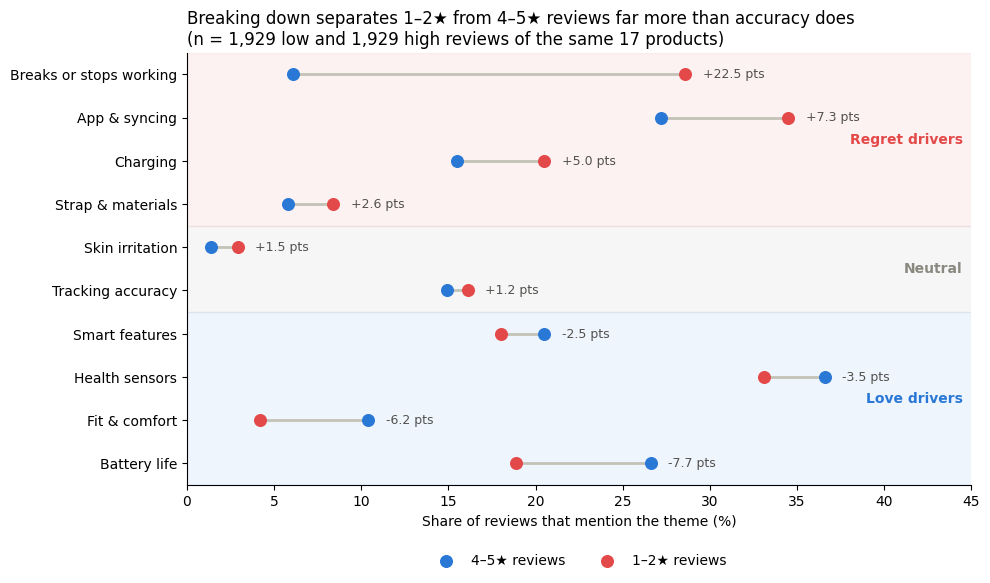

,role,median gap per product (pts),products where low > high
Breaks or stops working,Regret driver,22.5,17 of 17
App & syncing,Regret driver,4.2,12 of 17
Charging,Regret driver,3.3,12 of 17
Strap & materials,Regret driver,0.9,11 of 17
Skin irritation,Neutral,1.1,12 of 17
Tracking accuracy,Neutral,0.8,9 of 17
Smart features,Love driver,-3.3,6 of 17
Health sensors,Love driver,-4.2,6 of 17
Fit & comfort,Love driver,-6.7,1 of 17
Battery life,Love driver,-8.0,2 of 17


In [8]:
# Each theme gets a role from its overall gap: regret driver (gap of +2 pts or more), love driver (−2 or less), neutral in between
ROLE = pd.cut(rates["gap (low − high)"], [-100, -2, 2, 100], right=False,
              labels=["Love driver", "Neutral", "Regret driver"]).astype(str)
ROLE_COLORS = {"Regret driver": LOW, "Neutral": "#8a8980", "Love driver": HIGH}

# Chart 3: how often each theme comes up in low vs high reviews, grouped by role
order = rates.sort_values("gap (low − high)").index
fig, ax = plt.subplots(figsize=(10, 6))
for role in ROLE_COLORS:
    rows = [i for i, t in enumerate(order) if ROLE[t] == role]
    ax.axhspan(min(rows) - 0.5, max(rows) + 0.5, color=ROLE_COLORS[role], alpha=0.07, zorder=0)
    ax.text(44.5, (min(rows) + max(rows)) / 2, role + "s" if role != "Neutral" else role,
            ha="right", va="center", fontsize=10, color=ROLE_COLORS[role], fontweight="bold")
for i, theme in enumerate(order):
    lo, hi = rates.loc[theme, "low %"], rates.loc[theme, "high %"]
    ax.plot([hi, lo], [i, i], color="#c3c2b7", linewidth=2, zorder=1)
    ax.scatter(hi, i, color=HIGH, s=70, zorder=2, label="4–5★ reviews" if i == 0 else None)
    ax.scatter(lo, i, color=LOW, s=70, zorder=2, label="1–2★ reviews" if i == 0 else None)
    ax.text(max(lo, hi) + 1, i, f"{lo - hi:+.1f} pts", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_ylim(-0.5, len(order) - 0.5)
ax.set_xlabel("Share of reviews that mention the theme (%)")
ax.set_xlim(0, 45)
ax.set_title("Breaking down separates 1–2★ from 4–5★ reviews far more than accuracy does\n"
             f"(n = {(reviews.low_rating).sum():,} low and {(~reviews.low_rating).sum():,} high reviews of the same 17 products)", loc="left")
ax.legend(frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.22))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Does the gap hold product by product, or is it driven by a few devices?
by_product = reviews.groupby(["short_name", "low_rating"])[list(THEMES)].mean().unstack("low_rating") * 100
gaps = pd.DataFrame({t: by_product[(t, True)] - by_product[(t, False)] for t in THEMES})
consistency = pd.DataFrame({
    "role": ROLE,
    "median gap per product (pts)": gaps.median().round(1),
    "products where low > high": (gaps > 0).sum().astype(str) + f" of {len(gaps)}",
}).loc[rates.sort_values("gap (low − high)", ascending=False).index]
display(consistency)

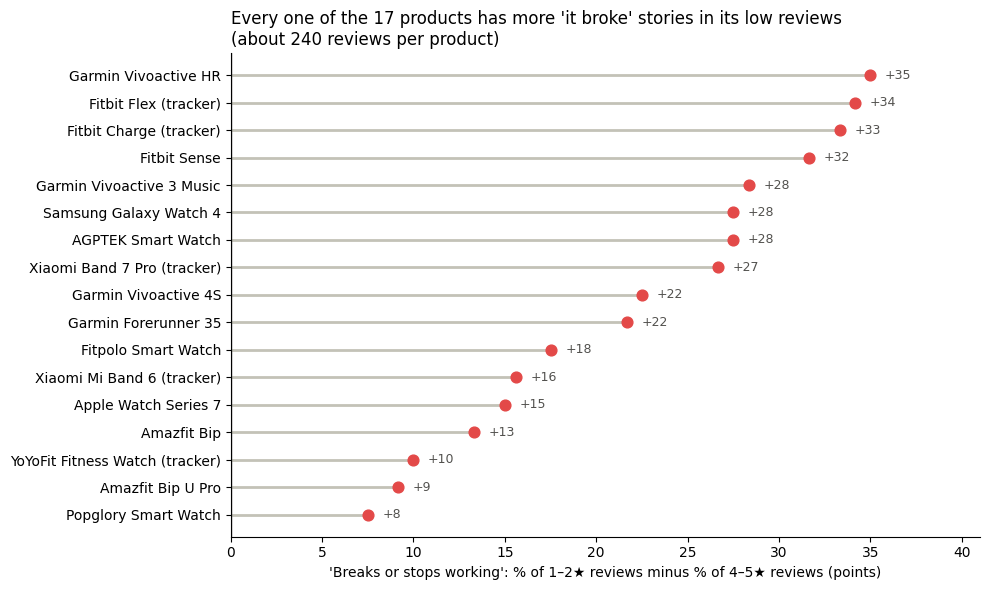

In [9]:
# Chart 4: the 'breaks' gap for every product (one dot per product)
breaks_gap = gaps["Breaks or stops working"].sort_values()
device = reviews.drop_duplicates("short_name").set_index("short_name")["device_type"]
labels = [f"{name} (tracker)" if device[name] == "fitness tracker" else name for name in breaks_gap.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(range(len(breaks_gap)), 0, breaks_gap.values, color="#c3c2b7", linewidth=2, zorder=1)
ax.scatter(breaks_gap.values, range(len(breaks_gap)), color=LOW, s=60, zorder=2)
for i, v in enumerate(breaks_gap.values):
    ax.text(v + 0.8, i, f"+{v:.0f}", va="center", fontsize=9, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(range(len(breaks_gap)))
ax.set_yticklabels(labels)
ax.set_xlim(0, breaks_gap.max() + 6)
ax.set_xlabel("'Breaks or stops working': % of 1–2★ reviews minus % of 4–5★ reviews (points)")
ax.set_title(f"Every one of the {len(breaks_gap)} products has more 'it broke' stories in its low reviews\n"
             f"(about {reviews.groupby('short_name').size().median():.0f} reviews per product)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What this shows**
- **Breaking down is the clearest signal, and it shows up for every product.** It appears in 29% of low reviews vs. 6% of high, and low reviews mention it more for all 17 products, from +8 points (Popglory) to +35 (Garmin Vivoactive HR). It isn't one bad device.
- **App & syncing and charging come next** (+7 and +5 overall, and low > high for 12 of 17 products). These are the problems of living with the device: it won't connect, or it won't charge.
- **Tracking accuracy hardly separates the groups** (+1.2 points, and low > high for only 9 of 17 products, about a coin flip). People mention accuracy at the same rate whether they're happy or not.
- **Comfort and battery life are praise themes.** They come up more in happy reviews for 16 and 15 of 17 products. When a wearable is comfortable and lasts, people notice and say so.

**So far:** the themes split into regret drivers and love drivers, and that split doesn't follow my two families. My expectation was half right. Wearability does separate the groups more than technical capability, but the separating part is durability (breaking, charging), not comfort. Accuracy, which I expected product teams to focus on, barely matters here.

### 2.7 Trackers vs. smartwatches

Trackers and smartwatches are different products at different prices, so I check whether the same gaps hold for both. Tracker reviews in my sample are also older on average, so I re-run the "breaks" gap on reviews from 2019 on.

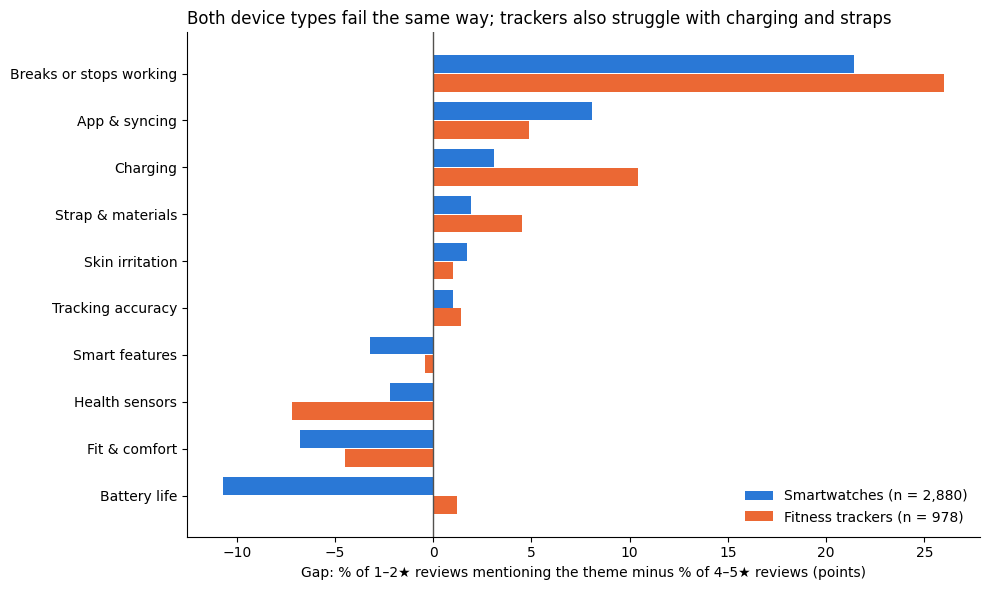

device_type,fitness tracker,smartwatch
Battery life,1.2,-10.7
Fit & comfort,-4.5,-6.8
Health sensors,-7.2,-2.2
Smart features,-0.4,-3.2
Tracking accuracy,1.4,1.0
Skin irritation,1.0,1.7
Strap & materials,4.5,1.9
Charging,10.4,3.1
App & syncing,4.9,8.1
Breaks or stops working,26.0,21.4


'Breaks' gap, reviews from 2019 on: {'fitness tracker': 18.3, 'smartwatch': 20.4} | reviews: {'fitness tracker': 500, 'smartwatch': 2503}


In [10]:
# Gap (low − high) for each theme, separately for trackers and smartwatches
type_rates = reviews.groupby(["device_type", "low_rating"])[list(THEMES)].mean().unstack("low_rating") * 100
type_gaps = pd.DataFrame({t: type_rates[(t, True)] - type_rates[(t, False)] for t in THEMES}).T.round(1)
type_gaps = type_gaps.loc[rates.sort_values("gap (low − high)").index]

fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(type_gaps))
ax.barh([i + 0.2 for i in y], type_gaps["smartwatch"], height=0.38, color="#2a78d6", label=f"Smartwatches (n = {(reviews.device_type == 'smartwatch').sum():,})")
ax.barh([i - 0.2 for i in y], type_gaps["fitness tracker"], height=0.38, color="#eb6834", label=f"Fitness trackers (n = {(reviews.device_type == 'fitness tracker').sum():,})")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(list(y))
ax.set_yticklabels(type_gaps.index)
ax.set_xlabel("Gap: % of 1–2★ reviews mentioning the theme minus % of 4–5★ reviews (points)")
ax.set_title("Both device types fail the same way; trackers also struggle with charging and straps", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(type_gaps)

# Tracker reviews are older, so check the 'breaks' gap on reviews from 2019 on only
recent = reviews[reviews["review_year"] >= 2019]
recent_gap = recent.groupby(["device_type", "low_rating"])["Breaks or stops working"].mean().unstack() * 100
recent_gap["gap"] = recent_gap[True] - recent_gap[False]
print("'Breaks' gap, reviews from 2019 on:", recent_gap["gap"].round(1).to_dict(),
      "| reviews:", recent.groupby("device_type").size().to_dict())

**What this shows**
- **Breaking down is the top gap for both** (+26 points for trackers, +21 for smartwatches). From 2019 on it's 18 vs. 20, so it isn't just old trackers wearing out.
- **Trackers have a second problem: charging and straps** (+10 and +5). Small proprietary chargers and thin bands seem to be where cheap trackers give out.
- **For smartwatches, battery life is a praise theme** (−11) and app & syncing is the second gap (+8). A smartwatch leans on the phone more, so when pairing fails the whole product fails.
- Trackers are only 5 products (978 reviews), so I treat the tracker numbers as a direction, not a precise figure.

### 2.8 Reading the reviews

Keyword counts tell me how often a theme comes up, not what people actually mean. So I read a random sample of 30 low and 30 high reviews (fixed seed so it can be repeated) and coded each one by hand. A review can get more than one code. Then I used keyword-in-context to check *when* devices fail.

In [11]:
# A documented reading sample: 30 random low and 30 random high reviews (fixed seed so it can be repeated)
reading_sample = reviews.groupby("rating_group", group_keys=False).sample(n=30, random_state=530)
for _, r in reading_sample.iterrows():
    print(f"{r.review_id} | {r.stars}★ | {r.short_name} | {r.full_text[:330]}\n")

R00485 | 5★ | Garmin Forerunner 35 | Better fitting. Had older model and this was an upgrade so far like it

R00940 | 5★ | Popglory Smart Watch | Stylish look. Multiple tracking and long lasting battery

R00100 | 5★ | Fitbit Charge | Great investment!. I am really glad I spent the money for this. For one thing, I'm a grad student and am reading/ sedentary most of the time. When I realized how little I was doing, I began to walk to local places (grocery store, the park, restaurants, etc.) instead of driving. Saves gas too. The watch and alarm are great. The w

R02668 | 5★ | Amazfit Bip U Pro | Great fitness watch for the price. I like that it is a full size watch and not a band style tracker. Yet it is very light weight so really like wearing nothing on your wrist.  app tracks heart rate, blood oxygen, sleep, and PAI.  Graphical display in app is nice.  If you use it a lot it probably won’t go 9 days without charge, b

R03804 | 5★ | Apple Watch Series 7 | What can I say it is a series 7

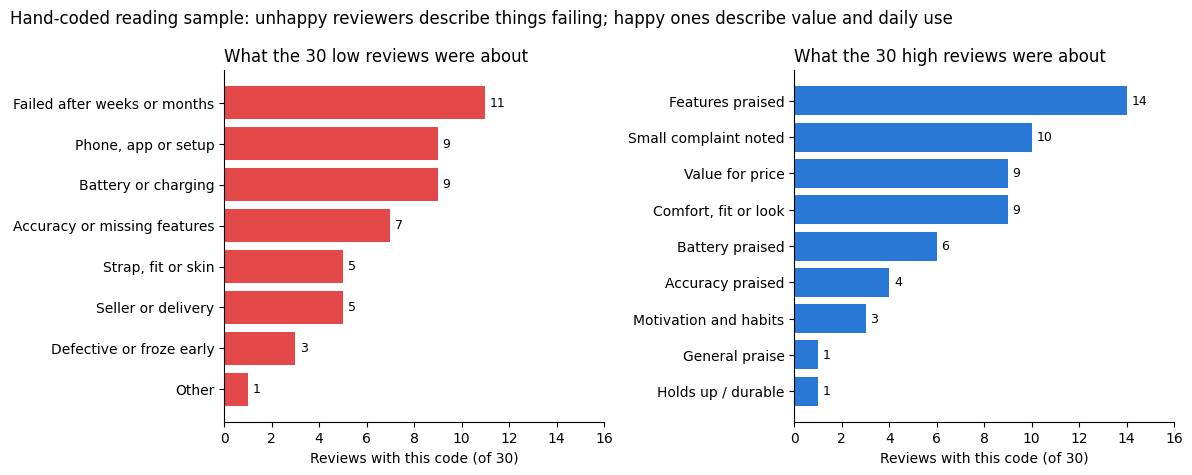

In [12]:
# My codes for each review I read (a review can have more than one)
LOW_CODES = {
    "R02556": ["Failed after weeks or months", "Battery or charging"], "R00971": ["Failed after weeks or months"],
    "R00963": ["Accuracy or missing features", "Phone, app or setup"], "R01739": ["Phone, app or setup", "Seller or delivery"],
    "R02484": ["Strap, fit or skin", "Failed after weeks or months", "Battery or charging"],
    "R02432": ["Failed after weeks or months", "Battery or charging"], "R02578": ["Other"],
    "R00193": ["Strap, fit or skin", "Failed after weeks or months", "Battery or charging"], "R01359": ["Seller or delivery"],
    "R01710": ["Accuracy or missing features"], "R00677": ["Phone, app or setup", "Defective or froze early"],
    "R01324": ["Phone, app or setup", "Seller or delivery"], "R01720": ["Strap, fit or skin", "Phone, app or setup"],
    "R02235": ["Defective or froze early", "Seller or delivery"],
    "R00641": ["Accuracy or missing features", "Phone, app or setup", "Battery or charging"],
    "R01577": ["Defective or froze early"], "R00661": ["Accuracy or missing features"], "R01363": ["Phone, app or setup"],
    "R03099": ["Failed after weeks or months", "Battery or charging", "Accuracy or missing features"],
    "R01666": ["Phone, app or setup", "Accuracy or missing features"], "R00625": ["Strap, fit or skin"],
    "R01332": ["Battery or charging"], "R03351": ["Accuracy or missing features"],
    "R02517": ["Failed after weeks or months", "Battery or charging"], "R02552": ["Failed after weeks or months", "Strap, fit or skin"],
    "R02973": ["Failed after weeks or months"], "R01614": ["Phone, app or setup"],
    "R02506": ["Failed after weeks or months", "Battery or charging"], "R02624": ["Failed after weeks or months"],
    "R02267": ["Seller or delivery"],
}
HIGH_CODES = {
    "R00485": ["Comfort, fit or look"], "R00940": ["Comfort, fit or look", "Battery praised", "Features praised"],
    "R00100": ["Motivation and habits", "Features praised"], "R02668": ["Value for price", "Comfort, fit or look", "Features praised", "Small complaint noted"],
    "R03804": ["Features praised", "Small complaint noted"], "R00900": ["Battery praised", "Accuracy praised"],
    "R04073": ["Value for price", "Comfort, fit or look"], "R01951": ["Battery praised", "Small complaint noted"],
    "R00929": ["Value for price", "Small complaint noted"], "R02103": ["Features praised"],
    "R00443": ["Motivation and habits", "Small complaint noted"], "R02711": ["Value for price", "Features praised"],
    "R03149": ["Accuracy praised", "Value for price", "Battery praised"], "R01465": ["Features praised"],
    "R02358": ["Features praised", "Holds up / durable"], "R03872": ["Small complaint noted"],
    "R02291": ["Battery praised", "Features praised"], "R00420": ["Features praised", "Comfort, fit or look"],
    "R04092": ["Value for price", "Small complaint noted"], "R03883": ["General praise"],
    "R02397": ["Value for price", "Accuracy praised"], "R04090": ["Battery praised", "Comfort, fit or look"],
    "R02114": ["Features praised"], "R02146": ["Comfort, fit or look", "Accuracy praised", "Small complaint noted"],
    "R04006": ["Features praised"], "R02674": ["Value for price", "Features praised", "Comfort, fit or look"],
    "R01559": ["Small complaint noted"], "R03197": ["Features praised", "Value for price"],
    "R00867": ["Comfort, fit or look"], "R00120": ["Motivation and habits", "Small complaint noted"],
}
assert set(LOW_CODES) | set(HIGH_CODES) == set(reading_sample["review_id"])

low_counts = pd.Series([c for codes in LOW_CODES.values() for c in codes]).value_counts().sort_values()
high_counts = pd.Series([c for codes in HIGH_CODES.values() for c in codes]).value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, counts, color, title in [(axes[0], low_counts, LOW, "What the 30 low reviews were about"),
                                 (axes[1], high_counts, HIGH, "What the 30 high reviews were about")]:
    ax.barh(counts.index, counts.values, color=color)
    for i, v in enumerate(counts.values):
        ax.text(v + 0.2, i, str(v), va="center", fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Reviews with this code (of 30)")
    ax.set_xlim(0, 16)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Hand-coded reading sample: unhappy reviewers describe things failing; happy ones describe value and daily use", x=0.01, ha="left")
plt.tight_layout()
plt.show()

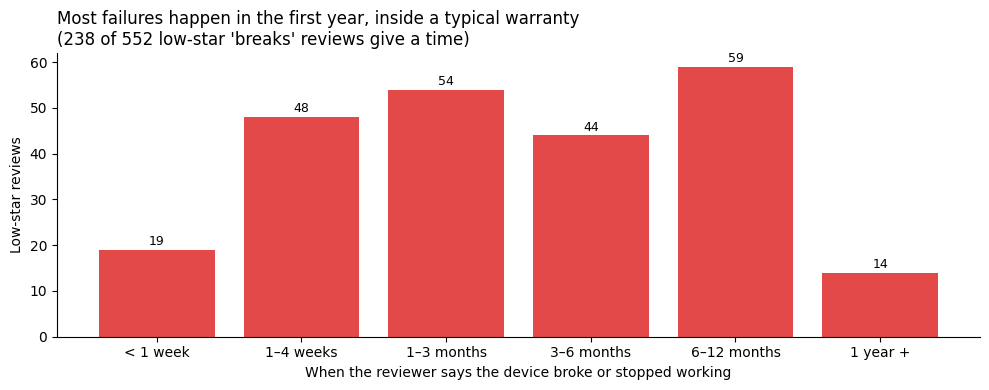

Within 6 months: 69% | within 12 months: 94%


In [13]:
# Keyword-in-context: when do people say their device failed?
NUM = {"a": 1, "an": 1, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7,
       "eight": 8, "nine": 9, "ten": 10, "eleven": 11, "twelve": 12, "few": 3, "couple": 2, "couple of": 2}
UNIT_MONTHS = {"day": 1 / 30, "week": 7 / 30, "month": 1, "year": 12}
TIME_PATTERN = (r"(?:after|within|in|lasted|only|less than|just over|about)\s+(?:only\s+|about\s+|just\s+)?"
                r"(\d+|a|an|one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|few|couple(?: of)?)\s+(day|week|month|year)s?")

failed = reviews[reviews["low_rating"] & reviews["Breaks or stops working"]].copy()
found = failed["full_text"].str.lower().str.extract(TIME_PATTERN)
failed["months"] = [(int(n) if str(n).isdigit() else NUM[n]) * UNIT_MONTHS[u] if isinstance(u, str) else None
                    for n, u in zip(found[0], found[1])]
timed = failed.dropna(subset=["months"])
buckets = pd.cut(timed["months"], bins=[0, 0.25, 1, 3, 6, 12, 1000], include_lowest=True,
                 labels=["< 1 week", "1–4 weeks", "1–3 months", "3–6 months", "6–12 months", "1 year +"])
when = buckets.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(when.index.astype(str), when.values, color=LOW)
for i, v in enumerate(when.values):
    ax.text(i, v + 1, str(v), ha="center", fontsize=9)
ax.set_ylabel("Low-star reviews")
ax.set_xlabel("When the reviewer says the device broke or stopped working")
ax.set_title(f"Most failures happen in the first year, inside a typical warranty\n"
             f"({len(timed)} of {len(failed)} low-star 'breaks' reviews give a time)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Within 6 months: {(timed['months'] <= 6).mean():.0%} | within 12 months: {(timed['months'] <= 12).mean():.0%}")

**Themes from reading**

1. **"It worked, then it didn't."** The most common story in low reviews (14 of 30) is a device that was fine at first and then failed: it stopped charging, froze, or the band snapped.
   - *"After six months, the watch is totally unresponsive. It doesn't charge and won't reset."* (R02556, 1★)
   - *"It was terrific at first but after two months it would not keep its charge."* (R02432)
   - *"The band broke of after 3 months of use."* (R02552)
   - *"This watch lasted exactly 8 months and 5 days... It fell apart in the shower."* (R02624)

2. **"It won't talk to my phone."** Nine low reviews are about pairing, updates or the app. When the app fails, people describe the watch itself as useless.
   - *"It would pair and launch then error and start the process over again."* (R01363)
   - *"update would not finish"* (R00677)
   - *"Without a decent software package the watch is useless."* (R01614)

3. **Happy reviewers talk about value, comfort and daily use, and treat accuracy as a caveat.** Ten of 30 high reviews mention a flaw and still give 4–5★.
   - *"accuracy is a little off... Overall, I'm happy"* (R04092)
   - Stairs not registering, but *"grown to truly enjoy"* it (R00120)
   - *"very light weight so really like wearing nothing on your wrist"* (R02668)

**Failure timing:** 238 of 552 low "breaks" reviews say when it happened. 69% fall within 6 months and 94% within a year, so most of these failures happen inside a typical warranty period.

**Counterexamples**
- Accuracy does sink some reviews: *"Battery life is great, heart rate tracking is terrible... up to 40% off"* (R03351, 2★), and R01710 on blood pressure readings that didn't match a cuff.
- 5 of 30 low reviews are really about the seller or delivery (wrong item, used unit, missing parts), not the product itself. My keyword themes can't separate these out.
- Reading found failure in 14 of 30 low reviews, while the keywords flagged only 8 of those 30, so the keyword count for "breaks" is probably conservative.
- The timing search can misread phrases like "about 5 days" of battery as a failure time. I spot-checked it and this was rare, but it's a caveat.

### 2.9 Does the main finding survive different choices?

Two choices could be driving my result:
1. **Review length.** Low reviews are longer (2.3), so they have more chances to mention anything. I split reviews into four length bands, compare low vs. high within each band, and average the gaps.
2. **The "breaks" word list.** Words like *warranty*, *replacement* and *dead* can describe customer service or a dead battery rather than a broken device. I re-run "breaks" with a stricter list without them.

In [14]:
# Choice 1: review length. Compare low and high reviews of similar length (four length bands), then average the gaps
reviews["length_band"] = pd.qcut(reviews["word_count"], 4, labels=["shortest", "short", "long", "longest"])
band_rates = reviews.groupby(["length_band", "low_rating"], observed=True)[list(THEMES)].mean().unstack("low_rating") * 100
band_gaps = pd.DataFrame({t: band_rates[(t, True)] - band_rates[(t, False)] for t in THEMES})

# Choice 2: a stricter "breaks" list without words that can also describe customer service (warranty, replacement, dead)
STRICT_BREAKS = r"stopped working|stop working|quit working|stops working|\bdied\b|\bbroke\b|\bbroken\b|fell (?:off|apart)|defective|malfunction\w*|won'?t turn on|cracked"
strict = reviews["full_text"].str.lower().str.contains(STRICT_BREAKS, regex=True)
strict_gap = (strict[reviews.low_rating].mean() - strict[~reviews.low_rating].mean()) * 100

compare = pd.DataFrame({
    "original gap (pts)": rates["gap (low − high)"],
    "length-matched gap (pts)": band_gaps.mean().round(1),
}).sort_values("original gap (pts)", ascending=False)
compare["original rank"] = compare["original gap (pts)"].rank(ascending=False).astype(int)
compare["length-matched rank"] = compare["length-matched gap (pts)"].rank(ascending=False).astype(int)
display(compare)
print("Reviews per length band:", reviews.groupby(["length_band", "rating_group"], observed=True).size().unstack().to_dict("index"))
print(f"'Breaks' gap with the stricter word list: {strict_gap:+.1f} pts (original {rates.loc['Breaks or stops working', 'gap (low − high)']:+.1f})")

,original gap (pts),length-matched gap (pts),original rank,length-matched rank
Breaks or stops working,22.5,20.8,1,1
App & syncing,7.3,1.8,2,3
Charging,5.0,2.1,3,2
Strap & materials,2.6,1.0,4,4
Skin irritation,1.5,1.0,5,4
Tracking accuracy,1.2,-1.8,6,6
Smart features,-2.5,-6.5,7,7
Health sensors,-3.5,-9.5,8,9
Fit & comfort,-6.2,-7.8,9,8
Battery life,-7.7,-10.8,10,10


Reviews per length band: {'shortest': {'high (4-5 stars)': 614, 'low (1-2 stars)': 371}, 'short': {'high (4-5 stars)': 490, 'low (1-2 stars)': 475}, 'long': {'high (4-5 stars)': 440, 'low (1-2 stars)': 505}, 'longest': {'high (4-5 stars)': 385, 'low (1-2 stars)': 578}}
'Breaks' gap with the stricter word list: +17.0 pts (original +22.5)


**What this shows**
- **Breaking down holds.** Matched for length it's still +21 points and still #1. With the stricter word list it's +17. It's the one gap that doesn't depend on my choices.
- **App & syncing mostly disappears** (+7 → +2). Most of that gap came from low reviews being longer, so I won't claim it as a strong separator.
- **Charging shrinks to +2**, and accuracy flips slightly negative. Comfort, battery, sensors and smart features stay praise themes.
- So the honest version of my finding is narrower than 2.6: **durability is the one robust separator.**

### 2.10 Pressure-testing the story

Before writing my conclusion I tested four ways it could be wrong:
1. Does wearability still separate the groups if I leave out "breaks"?
2. Are happy reviews just written earlier, before anything had time to fail?
3. Is battery really a praise theme, or do low reviews mention it as a complaint?
4. Is breaking just a problem with cheap, no-name watches?

In [15]:
# Check 1: does wearability still separate the groups once "breaks" is left out?
wear_no_breaks = [t for t in THEMES if FAMILY[t] == "Wearability" and t != "Breaks or stops working"]
family_check = pd.DataFrame({
    "Wearability (all 6 themes)": reviews["any_wearability"],
    "Wearability without 'breaks'": reviews[wear_no_breaks].any(axis=1),
    "Technical (all 4 themes)": reviews["any_technical"],
}).groupby(reviews["rating_group"]).mean().T * 100
family_check["gap (low − high)"] = family_check["low (1-2 stars)"] - family_check["high (4-5 stars)"]
display(family_check.round(1))

# Check 2: when are reviews written? Happy reviews may be first impressions, before anything has had time to fail
text = reviews["full_text"].str.lower()
TIMING = {
    'Says "so far"': r"\bso far\b",
    "Describes months or years of use": r"(?:for|after|had it|owned it|wearing it|using it)[^.]{0,20}(?:\d+|several|few|many|two|three|six) (?:months|years)",
}
timing = pd.DataFrame({k: text.str.contains(p, regex=True) for k, p in TIMING.items()}).groupby(reviews["rating_group"]).mean().T * 100
display(timing.round(1))

# Check 3: a theme mention isn't always praise or complaint. How many battery mentions sound negative?
BATTERY_NEG = r"drain|dies|died|doesn'?t last|does not last|won'?t hold|not hold|poor|terrible|bad|short|only lasts|barely"
battery = reviews[reviews["Battery life"]]
print("Battery mentions that sound negative:",
      (battery["full_text"].str.lower().str.contains(BATTERY_NEG, regex=True).groupby(battery["rating_group"]).mean() * 100).round(1).to_dict())

# Check 4: is "breaks" just a cheap-watch problem?
BUDGET = {"YoYoFit", "Popglory", "AGPTEK", "Fitpolo"}
reviews["brand_tier"] = reviews["brand"].isin(BUDGET).map({True: "budget brand", False: "name brand"})
tier = reviews.groupby(["brand_tier", "rating_group"])["Breaks or stops working"].mean().unstack() * 100
tier["gap (low − high)"] = tier["low (1-2 stars)"] - tier["high (4-5 stars)"]
tier["products"] = reviews.groupby("brand_tier")["parent_asin"].nunique()
display(tier.round(1))

rating_group,high (4-5 stars),low (1-2 stars),gap (low − high)
Wearability (all 6 themes),43.5,54.0,10.5
Wearability without 'breaks',41.3,39.4,-1.9
Technical (all 4 themes),57.3,60.1,2.8


rating_group,high (4-5 stars),low (1-2 stars)
"Says ""so far""",7.2,1.0
Describes months or years of use,3.7,10.6


Battery mentions that sound negative: {'high (4-5 stars)': 15.8, 'low (1-2 stars)': 51.5}


rating_group,high (4-5 stars),low (1-2 stars),gap (low − high),products
brand_tier,,,,
budget brand,6.6,23.2,16.6,4
name brand,5.9,30.1,24.2,13


**What this shows**
- **Wearability only "wins" because of breaking.** Without it, wearability themes come up about equally in low and high reviews (39% vs. 41%). That's the exact condition I set in Section 1 for changing my mind. Neither family separates the groups; whether the device keeps working does.
- **Happy reviews are often first impressions.** "So far" shows up in 7% of high reviews vs. 1% of low ones, and low reviews describe months or years of use about three times as often (11% vs. 4%). Part of the breaks gap is timing: a 5★ review written in week one can't mention a failure in month four. People love a wearable early and regret it later.
- **Battery cuts both ways.** About half the battery mentions in low reviews sound negative, vs. 16% in high reviews. It's more common in happy reviews overall, but I can't call it purely a praise theme.
- **It isn't just cheap watches.** The breaks gap is actually larger for name brands (+24 points across 13 products) than for budget brands (+17 across 4).

### 2.11 What do the listings promise? (supporting question 4)

My premise is that wearables are sold on specs. The products table has each listing's feature bullets, so I run the same theme keywords on them. This is 16 listings, not a big sample, so I treat it as supporting context rather than a finding.

96 bullets from 16 of 17 listings


,count
family,
technical only,53
both,19
wearability only,12
no theme,12


First bullet of each listing: {'technical only': 9, 'both': 6, 'wearability only': 1}


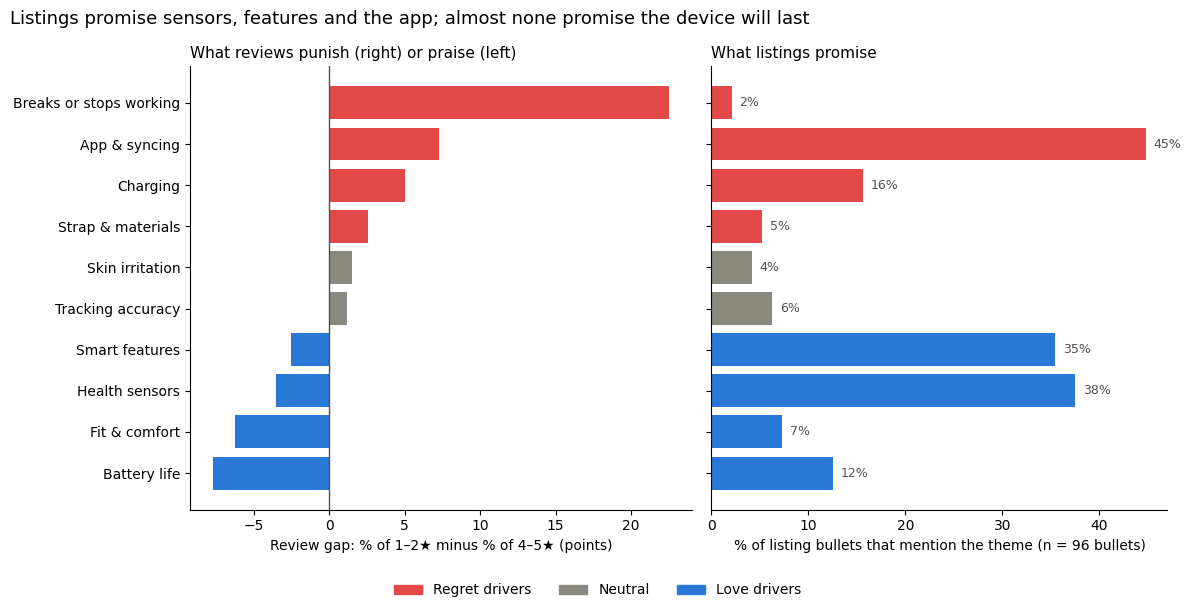

- More than 15 preloaded sports apps, including yoga, running, swimming, strength training and many more; The nexgadget replacement for Garmin charger is perfect compatible with our Vivoactive 3, we hig
- APPLECARE — Every Apple Watch comes with one year of hardware repair coverage through its limited warranty and up to 90 days of complimentary technical support. Get AppleCare+ to extend your coverage 


In [16]:
# Split each listing's feature text into bullets and code them with the same theme keywords
bullets = (products.assign(bullet=products["listing_features"].str.split(" | ", regex=False))
           .explode("bullet").dropna(subset=["bullet"]))
bullets = bullets[bullets["bullet"].str.strip() != ""]
for t, pattern in THEMES.items():
    bullets[t] = bullets["bullet"].str.lower().str.contains(pattern, regex=True)
print(f"{len(bullets)} bullets from {bullets['parent_asin'].nunique()} of {len(products)} listings")

def bullet_family(row):
    w = any(row[t] for t in THEMES if FAMILY[t] == "Wearability")
    tech = any(row[t] for t in THEMES if FAMILY[t] == "Technical")
    return "both" if w and tech else "wearability only" if w else "technical only" if tech else "no theme"
bullets["family"] = bullets.apply(bullet_family, axis=1)
display(bullets["family"].value_counts())
print("First bullet of each listing:", bullets.groupby("parent_asin").first()["family"].value_counts().to_dict())

# Chart 9: what reviews punish next to what listings promise, theme by theme
order = rates.sort_values("gap (low − high)").index
listing_share = bullets[list(THEMES)].mean().loc[order] * 100
colors = [ROLE_COLORS[ROLE[t]] for t in order]

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 6), sharey=True, gridspec_kw={"width_ratios": [1.1, 1]})
left.barh(order, rates.loc[order, "gap (low − high)"], color=colors)
left.axvline(0, color="#52514e", linewidth=1)
left.set_xlabel("Review gap: % of 1–2★ minus % of 4–5★ (points)")
left.set_title("What reviews punish (right) or praise (left)", loc="left", fontsize=11)
right.barh(order, listing_share, color=colors)
for i, v in enumerate(listing_share):
    right.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color="#52514e")
right.set_xlabel(f"% of listing bullets that mention the theme (n = {len(bullets)} bullets)")
right.set_title("What listings promise", loc="left", fontsize=11)
for a in (left, right):
    a.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ROLE_COLORS.values()],
           labels=[r + "s" if r != "Neutral" else r for r in ROLE_COLORS], frameon=False, ncol=3,
           loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Listings promise sensors, features and the app; almost none promise the device will last", x=0.01, ha="left", fontsize=13)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

# What do the few durability bullets actually say?
for b in bullets.loc[bullets["Breaks or stops working"], "bullet"]:
    print("-", b[:200])

**What this shows**
- **Listings lead with technical features.** 53 of 96 bullets mention only technical themes and 12 mention only wearability. The first bullet is technical for 9 of 16 listings and wearability-only for just one.
- **Almost nothing promises durability**, the biggest regret driver: 2% of bullets, and one of those two is a false match (a replacement charger). The only real one is Apple's line about warranty coverage.
- **The app is the most-promised theme (45%) and also a regret driver.** Most of those bullets are about syncing with your phone, which is exactly what low reviews say doesn't work. That gap shrank once I matched review length (2.9), so I treat it as a hint, not a finding.
- Sensors and smart features, the other big promises, are love drivers: listings sell what happy owners enjoy, and stay quiet about whether the device will last.

### 2.12 Summary of patterns

I set out to ask whether wearability or technical capability separates loved wearables from regretted ones. The honest answer is neither family as a whole. What separates them is whether the device keeps working. "Breaks or stops working" shows up more in low reviews for all 17 products, for trackers and smartwatches, for name brands and budget brands, after matching for review length, and with a stricter word list. Leave it out and wearability themes come up about equally in happy and unhappy reviews.

The themes split by role instead of by family. Breaking, charging, app problems and straps show up when people regret a device (the app gap is partly a review-length effect). Comfort, battery, health sensors and smart features show up more when they love it. Accuracy shows up equally in both, and happy reviewers mention its flaws and still give 4–5★. Durability is a basic expectation that nobody praises when it works but everybody punishes when it fails, while features and comfort are what earn the 5 stars. Reviews can't prove that, though. A happy reviewer may just not have had the device long enough to see it fail, so I treat it as a hypothesis to test, not a finding. Listings lead with sensors, smart features and phone syncing, and almost never mention whether the device will last.

**What the data can't tell me:** these are written Amazon reviews, which skew toward people motivated to write, so the rates describe reviewers, not all owners. Happy reviews are often written early, so some of today's 5★ devices may fail later, and I can't follow anyone over time. Keyword coding can't tell praise from complaint, and my 60-review reading sample is small. I can't see return rates, how long people kept the device, or whether a failure was the design or one bad unit. With 17 products (a third of the smartwatches are Garmin), this is a pattern across these devices, not a rule for every wearable.

**Saving the cleaned data.** This writes the cleaned reviews with their theme flags to `wearable_reviews_clean.csv`, the data behind every result above. The field guide at the end explains each column.

In [17]:
# Cleaned reviews with theme flags: the data behind the results in Section 2
clean_cols = ["review_id", "parent_asin", "short_name", "brand", "product_title", "device_type", "rating_group", "stars", "low_rating",
              "review_title", "review_text", "word_count", "helpful_vote", "verified_purchase", "review_date", "review_year",
              "reviewer"] + list(THEMES) + ["any_wearability", "any_technical"]
reviews[clean_cols].to_csv("wearable_reviews_clean.csv", index=False)
print("Saved wearable_reviews_clean.csv:", reviews[clean_cols].shape)

Saved wearable_reviews_clean.csv: (3858, 29)


## 3. A/B test: checking in before people give up

**What I found.** My main result is that what separates 1–2★ from 4–5★ reviews isn't wearability or specs. It's whether the device keeps working. "Breaks or stops working" showed up more in low reviews for all 17 products, even after I matched review length and used a stricter word list. People treat it as a basic expectation: almost nobody praises a watch for not breaking, but everyone punishes it when it does.

What stood out to me is the timing. 94% of the failures with a date happened in the first year, so most of these devices were probably still under warranty. But only 6% of low reviews mention the warranty, while 19% mention returning it (vs. 2% of high reviews, a rough keyword count). And the listings barely mention durability at all.

**What I want to test.** My guess is that when a wearable fails early, people give up because getting it fixed feels like a hassle, not because there's no fix. If the brand checks in first and makes the fix easy, more people should end up with a working device they keep wearing.

**Why it matters.** No team can make every unit perfect, and durability won't earn anyone 5 stars. But it's the one thing that reliably earns 1 star, and what happens after a failure is something the team fully controls.

**What my data can't tell me.** Reviews show that people are unhappy, not whether they stopped wearing the device. I can't follow anyone over time or see why they skipped the warranty. That's what the test is for.

### A vs. B
- **A:** the current app. Support and warranty info lives in settings.
- **B:** the same app, plus a check-in at day 30 and day 90 asking *"Is your device working the way it should?"* Tapping **No** opens a quick troubleshooting step and a one-tap replacement request.

Nothing else changes: same devices, warranty and support team.

**Prediction:** We expect that adding an early check-in will lead to more people still wearing their device at day 180, because people with a failing unit will get it fixed or replaced instead of giving up on it.

### Who's in it
- New US owners of one brand's trackers and smartwatches who set up their device in the app during an 8-week window. No existing owners or refurbished units.
- The app randomly puts each new account in A or B at setup, 50/50, separately for each device model so both groups get the same mix. Nobody chooses or knows there are two versions.
- Both versions run at the same time, and the group is saved to the account, so reinstalling the app or getting a replacement doesn't move anyone.

### How I'd measure it
**Main measure:** the share of people still wearing their device at day 180, meaning their account recorded heart-rate data on the wrist at least once in days 166–180 (on the original or a replacement). Everyone assigned counts, including people who returned it or ignored the check-in.

I picked day 180 instead of day 30 because my data shows people love a wearable at first and regret it later. A short window would just catch the honeymoon. Recruitment closes after 8 weeks, and I'd wait until the last person hits day 180 before comparing.

### What would make B worth it
I'd adopt B if it raises the day-180 number by at least **2 percentage points**. The check-in is cheap to build, but every extra replacement costs money, so the gain has to be big enough to cover that.

**Side effect I'd watch:** replacement requests per 100 people. One-tap replacement could push people into swapping a device that troubleshooting would have fixed. They'd go days without it, the brand would pay for it, and the hardware wouldn't get any better.

### Ways this could fool me
1. **Measuring unevenly.** The check-in makes B users open the app, so app opens would look better in B even if nobody wore the device more. That's why I measure wear time on the wrist, which counts the same in both groups.
2. **Calling it early.** If B looks good at day 60, it'd be tempting to stop. I'd lock in day 180 and the 2-point bar before starting and not peek.

**Where it might not apply:** cheap generic watches like YoYoFit or Popglory, which have no real warranty or app. They break too, but there's no one to check in.

### If B wins
First I'd make sure the groups started out the same, that the gain really comes from people who tapped "No" and got a fix, and that replacements didn't get out of hand. If that holds, I'd **adopt B**. If wear goes up but replacements cost too much, I'd **revise** and try a version that pushes troubleshooting before replacement. If there's no real difference, I'd **keep A**, which would point back to the hardware itself (charging, straps, build).

This ties back to my main argument. Features and comfort earn the 5 stars, and that's what listings sell. Durability is what loses them, and nobody talks about it. If B works, the next thing I'd test is the listing itself: promising the support B makes real instead of leading with another spec.

## 4. Dashboard

**Live:** [https://wearables-portfolio-hmgmaecqh2rrjigame7xqj.streamlit.app/](https://wearables-portfolio-hmgmaecqh2rrjigame7xqj.streamlit.app/). It's also embedded on my [portfolio page](https://wearables-portfolio.vercel.app). The source is in `dashboard/` in my submission and on [GitHub](https://github.com/Aidan-OD-tech/wearables-portfolio).

The dashboard is for designers and product people who want the answer and the evidence without reading this notebook. It's one screen, top to bottom:
1. **The question and my answer**, right at the top.
2. **Filters:** device type (all, trackers, smartwatches) and a product picker. The review and product counts next to the filters update with every change. If no product is picked, it says so instead of showing empty charts.
3. **Three number tiles** for the main question: breaking, any wearability theme and any technical theme. Each one shows the share of low and high reviews, the gap in points and the counts behind it.
4. **The theme chart** from 2.6 (red 1–2★, blue 4–5★), recalculated for the selection. The themes stay in a fixed order, so the dots move instead of the rows.
5. **What people say:** pick a theme and a star group to read real reviews with their stars, product and review ID, with the matching words highlighted. This is the qualitative part.
6. **Fixed findings:** failure timing, what listings promise, what it means and the limits. These don't change with the filters, so they're labeled "All 17 products, 3,858 reviews · the filters don't change these".

It uses the same cleaning (2.2) and theme keywords (2.5) as this notebook, so with everything selected the tiles match 2.6 (+22.5, +10.5 and +2.8 points).

**To run it on your own computer** (Python 3.10 or newer):
```
cd dashboard
pip install -r requirements.txt
streamlit run app.py
```
It opens at http://localhost:8501. The hosted version goes to sleep when nobody has used it for a while. If it shows a button to wake it up, click it and give it a minute.

### 4.1 Layout sketch

I sketched the layout before building anything: one laptop screen with no tabs, the answer first, and the findings the filters can't change kept apart at the bottom.

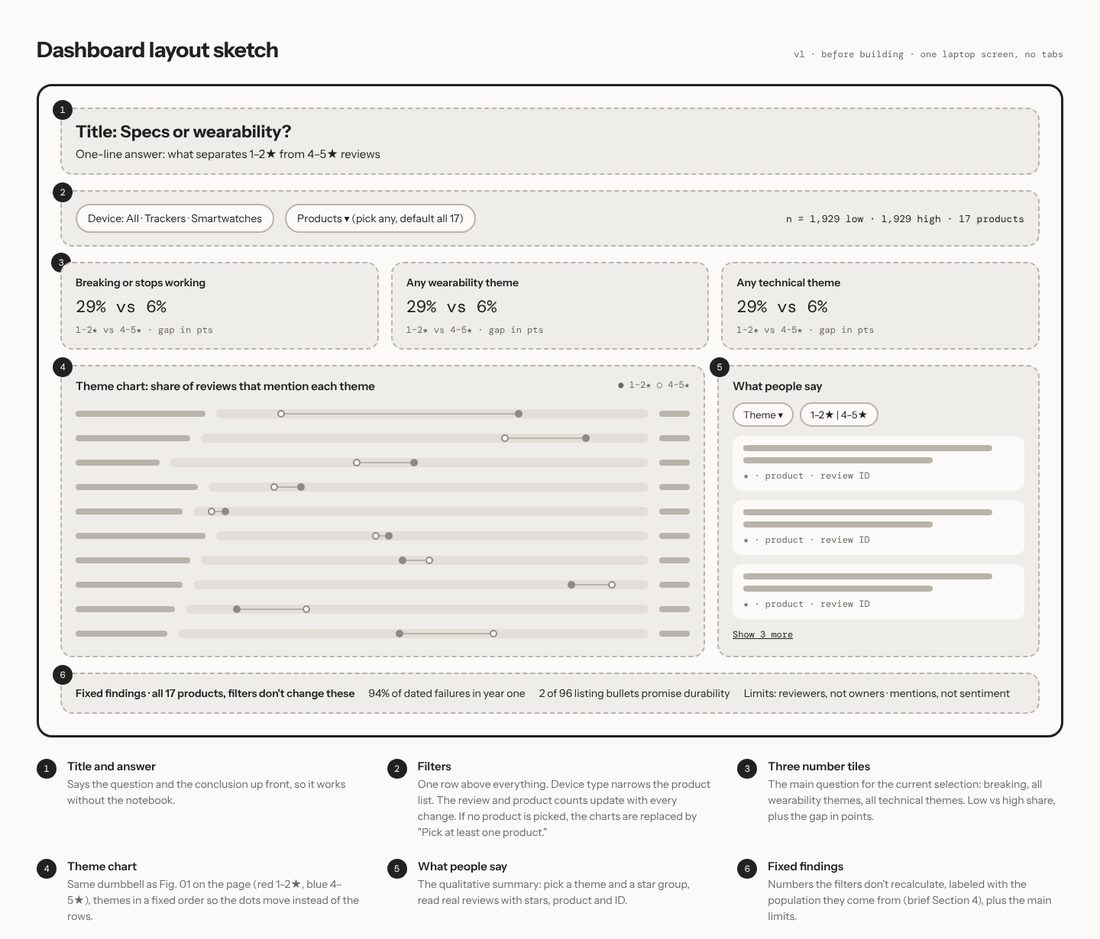

### 4.2 One design revision

**The tiles show counts, not just percentages.** In the sketch, each tile only had two shares, like "29% vs 6%". Once I built it and started filtering, that wasn't enough. Products have between 50 and 120 reviews in each group, so with one product picked a share like 40% can rest on as few as 50 reviews, and the tile gave no hint of that. So I added a line under each tile with the counts behind the shares, like "552 of 1,929 low vs 117 of 1,929 high reviews mention it".

The built version, with all products selected:

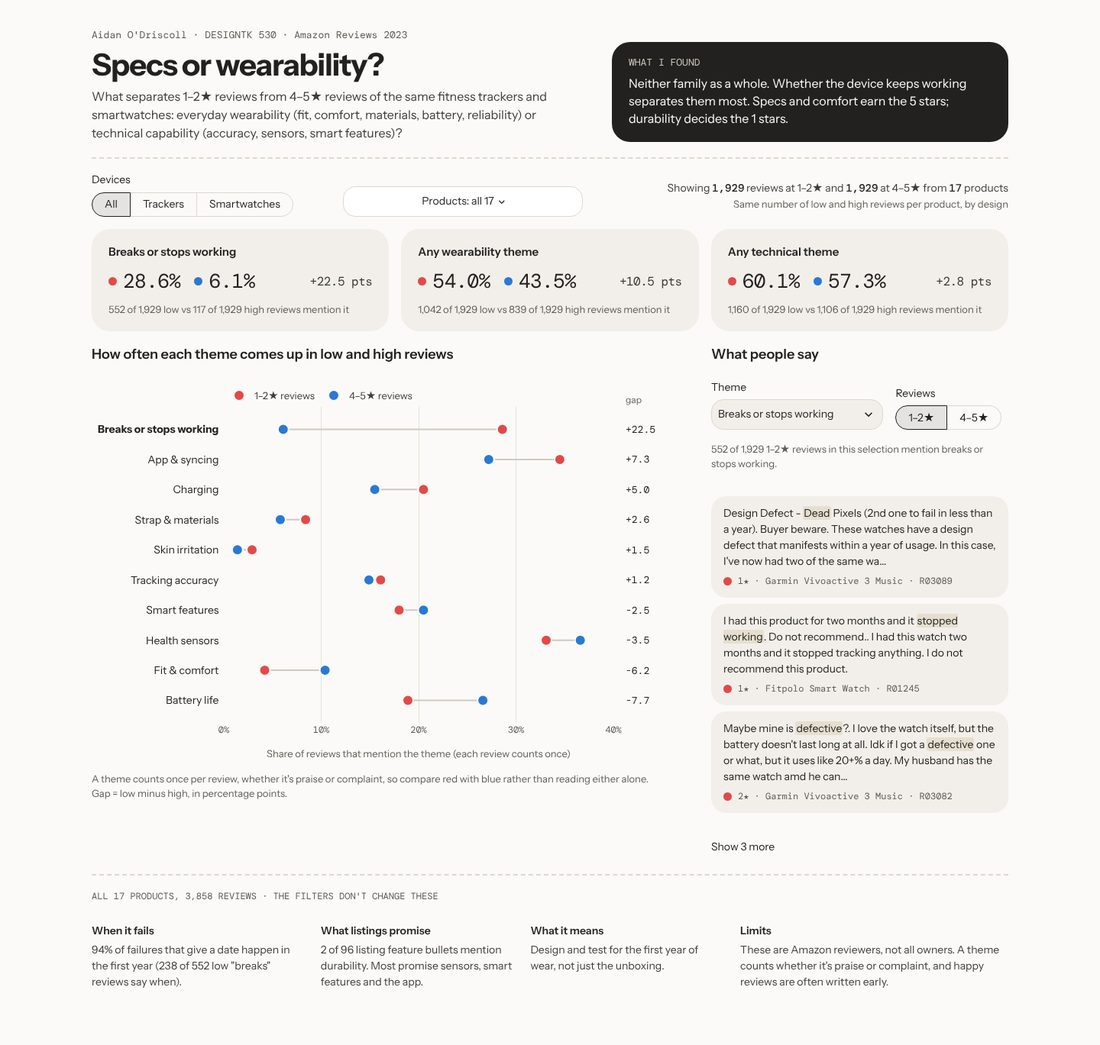

## 5. Checking my work against an AI tool

I wanted to see whether an AI would reach the same answer from the same data, and whether it could poke holes in mine. I used ChatGPT in two rounds on 14 Oct 2026, in one chat:

- **Round 1:** I gave it both CSVs, a description of the data and my main and supporting questions, but none of my themes, numbers or conclusions. I asked it to clean the data, code the themes its own way and answer each question.
- **Round 2:** I gave it my headline numbers and my 2.12 summary and asked it to critique them, checking claims against the data.

The full prompts are in 5.6. The full responses, ChatGPT's script and its output CSVs are in `ai_comparison/` in my submission, and the chat is [here](https://chatgpt.com/share/6acf537c-7b40-83ea-807e-805940bebc31).

### 5.1 What ChatGPT concluded on its own (Round 1)

> "Everyday-use experiences distinguish poorly rated wearables from highly rated ones more clearly than technical capabilities do. The strongest individual theme is reliability."

| ChatGPT, Round 1 | Low (n = 2,049) | High (n = 2,048) | Gap |
|---|---|---|---|
| Reliability / failure | 28.0% | 4.8% | +23.2 |
| Any everyday-use theme | 63.9% | 52.0% | +12.0 |
| Any technical theme | 58.2% | 56.9% | +1.2 |
| Materials / build | 21.4% | 17.1% | +4.3 |

### 5.2 Where we agree

- **Breaking is the biggest gap.** ChatGPT found it at +23.2 points, higher in low reviews for every product. Mine is +22.5, 17 of 17 products. We got there with different word lists, which makes me more confident it's real and not a product of my keywords.
- **Technical themes barely separate the groups** (its +1.2, my +2.8), and accuracy doesn't separate them at all.
- **Comfort shows up more in happy reviews** (its −6.1, my −6.2).
- **Listings lead with technical features.** It also caught the Gear IconX being earbuds and the HTML in the text, without me pointing them out.

### 5.3 Where we differ

ChatGPT's headline is that everyday use beats technical capability (+12.0 vs +1.2). That's what I expected going in, and what my own family-level numbers said in 2.6. But in 2.10 I found that the wearability gap disappears once breaking is left out. ChatGPT never ran that check, so I ran it on my data using its own word lists.

Two things I checked in its reasoning:
1. **Its "everyday use" gap is all reliability.** Without reliability, its everyday-use themes come up in 48.3% of low reviews vs 49.0% of high. That's the same near-tie I found (39.4% vs 41.3%).
2. **Materials/build isn't a second signal.** Its pattern counts "broke", "broken" and "cracked", which is breaking again, and bare "band", which matches "Mi Band". Take out the break words and the gap is 0.2 points.

In [18]:
# Checking ChatGPT's two Round 1 claims on my cleaned data, using its own keyword patterns (copied from its script)
GPT = {
    "fit_comfort": r"\b(?:comfort(?:able)?|uncomfortable|fit|fits|fitting|tight|loose|bulky|lightweight|light-weight|heavy|itch\w*|rash|irritat\w*|pinch\w*|chafe\w*|skin irritation|sleep with|wear(?:ing)? (?:it|this|the watch|my watch|a watch|all day|to bed|overnight|daily)|wearable|wore (?:it|this|the watch)|all-day wear|all day wear)\b",
    "materials_build": r"\b(?:bands?|straps?|silicone|rubber|leather|metal|plastic|stainless steel|materials?|build quality|durab\w*|broke|broken|crack\w*|scratch\w*|clasp|buckle|flimsy|waterproof|water[- ]resistant|water resistance|peel\w*|fall apart|cheaply made|cheap band)\b",
    "battery_charging": r"\b(?:batter(?:y|ies)|chargers?|charging|recharg\w*|battery life|hold\w* (?:a )?charge|full charge|need\w* to charge|have to charge|charge it|charge overnight|charge every|charge once|charge daily|charging time|charge time|charge lasts?|charge lasted|charge would not|charge wouldn't|can't get a charge|cannot get a charge|not hold a charge|lasts?\b.{0,35}\bcharge\b)\b",
    "reliability": r"\b(?:stopped working|stop\w* working|quit working|no longer work\w*|doesn.t work|does not work|not working|won.t work|fail(?:ed|ure|ing)?|defect\w*|malfunction\w*|glitch\w*|freez\w*|froze|reboot\w*|restart\w*|reset\w*|unreliab\w*|not dependab\w*|not reliable|shut(?:s|ting)? down|shut off|crash(?:es|ed|ing)?|software bug|hardware issue|bricked|fell apart|keeps? stopping|keeps? restarting)\b",
}
BREAK_WORDS = r"\b(?:broke|broken|crack\w*|fall apart|fell apart)\b"

gpt = pd.DataFrame({k: reviews["full_text"].str.contains(p, case=False, regex=True) for k, p in GPT.items()})
gpt["Everyday use (ChatGPT's 4 themes)"] = gpt[list(GPT)].any(axis=1)
gpt["Everyday use without reliability"] = gpt[["fit_comfort", "materials_build", "battery_charging"]].any(axis=1)
gpt["Materials/build without break words"] = gpt["materials_build"] & ~reviews["full_text"].str.contains(BREAK_WORDS, case=False, regex=True)

check = gpt.groupby(reviews["rating_group"]).mean().T * 100
check["gap (low − high)"] = check["low (1-2 stars)"] - check["high (4-5 stars)"]
display(check.loc[["reliability", "Everyday use (ChatGPT's 4 themes)", "Everyday use without reliability",
                   "materials_build", "Materials/build without break words"]].round(1))

rating_group,high (4-5 stars),low (1-2 stars),gap (low − high)
reliability,4.7,28.9,24.3
Everyday use (ChatGPT's 4 themes),50.6,63.9,13.3
Everyday use without reliability,49.0,48.3,-0.7
materials_build,17.8,22.6,4.8
Materials/build without break words,15.6,15.8,0.2


It also left out a few things I'd done:
- It didn't control for review length. Low reviews are longer in its data too (median 54 vs 40 words). Re-running its coded file within length bands cuts the everyday-use gap from +12.0 to +6.2, while reliability holds at +21.6.
- It merged battery and charging into one theme (−3.8), which hides that battery life comes up more in happy reviews and charging more in unhappy ones.
- It didn't read any reviews, so it had no way to see the "worked, then didn't" pattern or the early "so far" reviews.
- It called the gap between `amazon_rating_count` and the star counts an unexplained mismatch. It isn't: `amazon_rating_count` is Amazon's total, including star-only ratings, so it's always the bigger number. That's why 2.3 says star averages look kinder than written reviews.

### 5.4 Its critique of my work (Round 2)

Once it saw my numbers, ChatGPT said my conclusion was "better than my original one" and re-coded the data with two failure word lists of its own. The breaking gap came out at +21.9 and +27.1, still higher in low reviews for all 17 products. It also matched my "so far" count (139 of 1,929 high reviews; I get 139 too).

Its main pushback:
- **"The move from review-topic patterns to a Kano model explanation"** is my weakest inference. Reviews can show that failure mentions are lopsided, but not that people take reliability for granted. A happy reviewer may just not have had the device long enough to see it fail.
- **The biggest alternative explanation is ownership time.** Happy reviews may be early, unhappy ones later, so the gap mixes "reliability matters" with "people had time to find out".
- **The timing number needs its denominator.** 69% within six months is 69% of the 238 reviews that say when, not of all 552.
- It asked whether my 30 low reviews for hand-coding were picked from all low reviews or only from ones that already matched "breaks".

### 5.5 What I accepted, rejected and changed

**Accepted: drop the Kano claim.** This is fair. I can't measure how people feel when reliability is there versus missing; I only have mentions in reviews that already have a star rating. I also brought in a model I don't know well enough to defend. So I took the name out of 2.12, kept the idea in plain words, and flagged it as a guess:

> *Before:* "This looks a lot like the Kano model: durability is a must-have that nobody praises when it works but everybody punishes when it fails, while features and comfort are what earn the 5 stars."
>
> *After:* "Durability is a basic expectation that nobody praises when it works but everybody punishes when it fails, while features and comfort are what earn the 5 stars. Reviews can't prove that, though. A happy reviewer may just not have had the device long enough to see it fail, so I treat it as a hypothesis to test, not a finding."

**Already covered, so no change:**
- *Ownership time:* this is the same "so far" problem I found in 2.10, and it's already in my limitations. ChatGPT made the case more clearly than I had, so I'll say it out loud in the presentation.
- *Timing denominator:* 2.8 already says "238 of 552… say when it happened. 69% fall within 6 months." I'll keep the "of those that say when" wording on my portfolio page too.
- *Reading sample:* it's a random 30 of all low and 30 of all high reviews (2.8, `random_state=530`), not only the "breaks" matches.
- *Name vs budget brands:* I did compare these explicitly in 2.10 (+24 vs +17), but ChatGPT is right that 4 budget products is too few to say price doesn't matter. I only claim the gap shows up in both.

**Rejected from Round 1:** grouping reliability with comfort, materials and battery into one "everyday use" score, and keeping the IconX earbuds. The first hides the actual finding; the second isn't a wrist wearable.

**What I verified myself:** every number I quote from ChatGPT above comes from its output files or my own re-run of its patterns on my cleaned data. Its Round 2 listing numbers (53 of 96 technical-only, 2 durability) match mine exactly, so I can't tell whether it re-ran that or repeated my figures. I don't rely on them.

### 5.6 Prompts

**Round 1** (with `wearable_products.csv` and `wearable_reviews_sample.csv` attached)

> I'm doing a data analysis project for a design class and I'd like you to analyze the same data on your own. Please use Python on the two attached CSVs and show your code and numbers.
>
> **Data.** Amazon Reviews 2023 (McAuley Lab, UCSD), Cell Phones & Accessories and Electronics categories, filtered to named fitness tracker and smartwatch models.
> - `wearable_products.csv`: one row per product (parent_asin). Device type, brand, price, average rating, Amazon's real star counts (n_1star to n_5star), and the listing's feature bullets (listing_features, separated by " | ").
> - `wearable_reviews_sample.csv`: one row per written review. rating, rating_group (low = 1–2★, high = 4–5★), review_title, review_text, helpful_vote, verified_purchase, review_date.
> - Sampling: for each product I took up to 120 random 1–2★ reviews and the same number of 4–5★ reviews (40+ characters). 3★ is excluded. So low vs high is balanced by design and doesn't reflect how common low ratings really are. The review file is raw, before any cleaning.
>
> **Main question:** Which experiences separate highly rated fitness trackers and smartwatches from poorly rated ones: everyday wearability (fit, comfort, materials, battery, reliability) or technical capability (tracking accuracy, sensors, smart features)?
>
> **Supporting questions**
> 1. How often do 1–2★ and 4–5★ reviews of the same products mention wearability themes compared with technical themes?
> 2. Which single theme shows the biggest gap between low and high ratings?
> 3. Do fitness trackers and smartwatches differ?
> 4. Do product listings lead with technical features more than wearability?
>
> **Please:**
> 1. Check and clean the data. Tell me anything you'd remove or fix, and why.
> 2. Give a few descriptive statistics with the n behind each.
> 3. Code the review text into themes (your own method), and compare how often each theme comes up in low vs high reviews.
> 4. Answer each question above with numbers, and quote 2–3 reviews (with review_id) that support your main answer.
> 5. State your overall conclusion, how confident you are, and the main limitations of this data and your method.

**Round 2** (same chat)

> Thanks. Here is my own analysis of the same data. Please critique it honestly. Don't just agree with me, and use the data you already have loaded to check any claim you doubt.
>
> **How my method differs from yours**
> - I dropped the Gear IconX earbuds before analysis: 17 products, 3,858 reviews (1,929 low, 1,929 high).
> - 10 keyword themes on title + text. Wearability: fit & comfort, skin irritation, strap & materials, battery life, charging, breaks or stops working. Technical: tracking accuracy, health sensors, smart features, app & syncing. Battery life and charging are separate. I removed false matches like "Google Fit" and "Mi Band".
> - I hand-coded a random 30 low + 30 high reviews, re-ran the gaps within four review-length bands, and re-ran "breaks" with a stricter word list.
>
> **Headline numbers (share of reviews mentioning, low vs high)**
> - Breaks or stops working: 28.6% vs 6.1% (+22.5). Low > high in 17 of 17 products. Length-matched +20.8; stricter word list +17.0.
> - App & syncing +7.3 (length-matched +1.8). Charging +5.0 (+2.1). Accuracy +1.2 (−1.8).
> - Praise themes: battery life −7.7, fit & comfort −6.2, health sensors −3.5, smart features −2.5.
> - Any wearability theme +10.5; any technical +2.8. Wearability without "breaks": 39.4% vs 41.3% (−1.9).
> - "So far" appears in 7.2% of high reviews vs 1.0% of low.
> - Hand-coded: 14 of 30 low reviews describe a device that worked, then failed. Of 552 low "breaks" reviews, 238 give a time; 69% within 6 months.
> - Listings: 53 of 96 feature bullets are technical-only, 12 wearability-only; durability appears in 2%.
>
> **My summary**
> > I set out to ask whether wearability or technical capability separates loved wearables from regretted ones. The honest answer is neither family as a whole. What separates them is whether the device keeps working. "Breaks or stops working" is the biggest gap for all 17 products, for trackers and smartwatches, for name brands and budget brands, after matching for review length, and with a stricter word list. Leave it out and wearability themes come up about equally in happy and unhappy reviews.
> >
> > The themes split by role instead of by family. Breaking, charging, app problems and straps show up when people regret a device (the app gap is partly a review-length effect). Comfort, battery, health sensors and smart features show up more when they love it. Accuracy shows up equally in both, and happy reviewers mention its flaws and still give 4–5★. This looks a lot like the Kano model: durability is a must-have that nobody praises when it works but everybody punishes when it fails, while features and comfort are what earn the 5 stars. Listings lead with sensors, smart features and phone syncing, and almost never mention whether the device will last.
>
> **Please:**
> 1. Which of my claims are well supported, and which are overstated or unsupported? Check at least two against the data.
> 2. Where does my conclusion differ from yours in your first answer? Which one do you think is right, and why?
> 3. Is the Kano model comparison fair, or a stretch?
> 4. What's the biggest weakness or alternative explanation I haven't dealt with?
> 5. What one change would you make before I present this?
>
> Please answer in the chat only, with no files or downloads. If you can't run code on the data right now, critique from the numbers above and say which claims you'd want to check.

## AI disclosure

I used two AI tools on this project. I made the decisions on topic, question, cleaning and conclusions, ran every cell myself in Colab, and checked the numbers I report against the output.

- **Claude (Anthropic)**, through a Claude project, as a working partner throughout:
  - wrote the data-pull notebook (`01_data_pull.ipynb`) and the product selection rules, which I revised after the first pull came back mostly non-wearables
  - suggested Part 2 code one cell at a time, which I ran and interpreted before moving on, and made the charts
  - helped draft and edit my markdown, which I rewrote in my own words
  - helped draft the A/B test proposal
  - built the Streamlit dashboard from my layout sketch, and the portfolio page (Next.js) from my outline and the design I picked. I checked the dashboard's numbers against 2.6.
  - set up the ChatGPT prompts in Section 5 and checked ChatGPT's numbers against my data
- **ChatGPT (OpenAI)**: only for the independent analysis and critique in Section 5. I didn't copy its code or text into my analysis. The one change it led to is the durability wording in 2.12.

## Sources

- **Data:** Amazon Reviews 2023, McAuley Lab, UC San Diego. https://amazon-reviews-2023.github.io/ (files on Hugging Face: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023). I used the Cell Phones & Accessories and Electronics review and metadata files.
- **Paper for the data:** Hou, Y., Li, J., He, Z., Yan, A., Chen, X., & McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation.* arXiv:2403.03952. https://arxiv.org/abs/2403.03952
- **Tools:** Python with pandas and matplotlib (this notebook), DuckDB (the data pull), Streamlit and Plotly (dashboard), Next.js (portfolio page).
- **AI tools:** see Section 5 and the AI disclosure. The ChatGPT chat is linked in Section 5.

## Files and field guide

| File | What it is |
|---|---|
| `ODriscoll_Mid_Term_Project.ipynb` | This notebook (Sections 1–5) |
| `01_data_pull.ipynb` | Pulls the products and reviews from Amazon Reviews 2023 and writes the two CSVs below. I ran it once in Colab; the outputs are saved in it. To get the data again, run it top to bottom. |
| `wearable_products.csv` | One row per product (18, including the Gear IconX I drop in 2.2) |
| `wearable_reviews_sample.csv` | One row per sampled written review (4,098), before cleaning. This notebook starts from it. |
| `wearable_reviews_clean.csv` | The cleaned reviews with theme flags (3,858), written at the end of Section 2 |
| `dashboard/` | The Streamlit dashboard: `app.py`, `requirements.txt`, `.streamlit/config.toml`, a README with run steps, and its own copy of the review CSV |
| `ai_comparison/` | ChatGPT's responses, script and output CSVs for Section 5 |

The portfolio page code is in the GitHub repo linked at the top.

**Reused work:** none. This topic and dataset are new for this project.

**`wearable_products.csv`**

| Field | Meaning |
|---|---|
| `parent_asin` | Amazon's product ID (groups color and size variants) |
| `device_type` | `fitness tracker` or `smartwatch` |
| `reviews_total` | Reviews of this product in the dataset |
| `low_with_text`, `high_with_text` | 1–2★ and 4–5★ reviews with at least 40 characters of text (the pool I sampled from) |
| `n_1star` … `n_5star` | Reviews at each star level |
| `first_review`, `last_review` | Dates of the first and last review |
| `brand` | Store name on Amazon |
| `product_title` | Listing title |
| `average_rating` | Amazon's average star rating |
| `amazon_rating_count` | Amazon's total ratings, including star-only ratings with no text |
| `price_usd` | Listed price, often missing |
| `listing_features` | The listing's feature bullets in one text field, separated by vertical bars |

**`wearable_reviews_sample.csv`**

| Field | Meaning |
|---|---|
| `review_id` | My ID for the review (R00001 …), used for quotes |
| `parent_asin`, `device_type`, `brand`, `product_title` | The product it reviews |
| `rating_group` | `low (1-2 stars)` or `high (4-5 stars)` |
| `rating` | Stars, 1–5 |
| `review_title`, `review_text` | What the reviewer wrote (raw, with some HTML codes) |
| `helpful_vote` | "Helpful" votes from other shoppers |
| `verified_purchase` | True if Amazon confirmed the purchase |
| `review_date` | Date posted |
| `reviewer` | Hashed reviewer ID, not the real account ID |

**`wearable_reviews_clean.csv`** has the fields above (with plain-text title and review, and `stars` in place of `rating`), plus:

| Field | Meaning |
|---|---|
| `short_name` | Short product name used in charts |
| `low_rating` | True for 1–2★ |
| `word_count` | Words in the review text |
| `review_year` | Year posted |
| 10 theme columns (`Fit & comfort` … `App & syncing`) | True if the title or review mentions the theme (keywords in 2.5) |
| `any_wearability`, `any_technical` | True if any theme in that family is mentioned |